In [23]:
import pandas as pd
import numpy as np
import os
import random
from bertopic import BERTopic
from umap import UMAP
from hdbscan import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer
from sentence_transformers import SentenceTransformer
from gensim.models.coherencemodel import CoherenceModel
from gensim.corpora import Dictionary
from sklearn.metrics import silhouette_score

# ========= 离线环境配置 =========
os.environ["TRANSFORMERS_OFFLINE"] = "1"
os.environ["HF_DATASETS_OFFLINE"] = "1"
os.environ["HF_HUB_OFFLINE"] = "1"

out_dir = r"D:\Jupyter\final_output_global"
os.makedirs(out_dir, exist_ok=True)

# ========= 1.读取全局完整数据集 =========
df_all = pd.read_excel("Now_Wuhan_PlanA_Cleaned.xlsx")
docs_global = df_all["cleaned_docs"].tolist()
print(f"全局总文档数：{len(docs_global)}")

# ========= 2.本地嵌入模型 =========
model_path = r"D:\Jupyter\all-MiniLM-L6-v2\snapshots\c9745ed1d9f207416be6d2e6f8de32d1f16199bf"
embedding_model = SentenceTransformer(model_path)

# ========= 3.停用词集合（原样沿用） =========
base_stopwords = {
    'i', 'me', 'my', 'myself', 'we', 'our', 'ours', 'ourselves', 'you',
    'your', 'yours', 'yourself', 'yourselves', 'he', 'him', 'his',
    'himself', 'she', 'her', 'hers', 'herself', 'it', 'its', 'itself',
    'they', 'them', 'their', 'theirs', 'themselves', 'what', 'which',
    'who', 'whom', 'this', 'that', 'these', 'those', 'am', 'is', 'are',
    'was', 'were', 'be', 'been', 'being', 'have', 'has', 'had', 'having',
    'do', 'does', 'did', 'doing', 'a', 'an', 'the', 'and', 'but', 'if',
    'or', 'because', 'as', 'until', 'while', 'of', 'at', 'by', 'for',
    'with', 'about', 'against', 'between', 'into', 'through', 'during',
    'before', 'after', 'above', 'below', 'to', 'from', 'up', 'down', 'in',
    'out', 'on', 'off', 'over', 'under', 'again', 'further', 'then',
    'once', 'here', 'there', 'when', 'where', 'why', 'how', 'all', 'any',
    'both', 'each', 'few', 'more', 'most', 'other', 'some', 'such', 'no',
    'nor', 'not', 'only', 'own', 'same', 'so', 'than', 'too', 'very',
    's', 't', 'can', 'will', 'just', 'don', 'should', 'now', 'd', 'll',
    'm', 'o', 're', 've', 'y', 'ain', 'aren', 'couldn', 'didn', 'doesn',
    'hadn', 'hasn', 'haven', 'isn', 'ma', 'mightn', 'mustn', 'needn',
    'shan', 'shouldn', 'wasn', 'weren', 'won', 'wouldn'
}

news_stopwords = {
    'said', 'says', 'say', 'told', 'tell', 'tells', 'reported', 'report',
    'reports', 'reporting', 'according', 'official', 'officially',
    'announced', 'announce', 'stated', 'state', 'based', 'added', 'per',
    'following', 'confirmed', 'noted', 'note', 'called', 'call',
    'accordingly', 'revealed', 'reveal', 'explained', 'explain',
    'pointed', 'point', 'mentioned', 'mention', 'claimed', 'claim',
    'described', 'describe',
    'reuters', 'ap', 'afp', 'bbc', 'photo', 'filephoto', 'getty',
    'credits', 'source', 'sources', 'via', 'nbsp',
    'also', 'just', 'very', 'still', 'well', 'around', 'like', 'including'
}

top100_stopwords = {
    'could', 'would', 'may',
    'one', 'two', 'three',
    'many', 'even', 'back',
    'first', 'last', 'late', 'early', 'since',
    'million', '000',
    'global', 'national', 'local', 'world',
    'new', 'major', 'severe', 'serious',
    'amid', 'during', 'ongoing', 'recent'
}
stop_words = base_stopwords.union(news_stopwords).union(top100_stopwords)

vectorizer_model = CountVectorizer(stop_words=list(stop_words), max_df=0.85, min_df=10)

# ========= 4.全套评价指标函数 =========
def calc_silhouette_sampling(topic_model, sample_size=8000, random_state=42):
    if hasattr(topic_model, 'umap_embeddings_') and topic_model.umap_embeddings_ is not None:
        umap_emb = topic_model.umap_embeddings_
    elif hasattr(topic_model.umap_model, 'embedding_'):
        umap_emb = topic_model.umap_model.embedding_
    else:
        return np.nan
    labels = np.array(topic_model.topics_)
    valid_mask = labels != -1
    valid_emb = umap_emb[valid_mask]
    valid_labels = labels[valid_mask]
    n_valid = len(valid_emb)
    if n_valid < 50:
        return np.nan
    rng = np.random.default_rng(random_state)
    if n_valid > sample_size:
        idx = rng.choice(n_valid, size=sample_size, replace=False)
        X_sample, y_sample = valid_emb[idx, :], valid_labels[idx]
    else:
        X_sample, y_sample = valid_emb, valid_labels
    return silhouette_score(X_sample, y_sample, metric='cosine')

def calc_cv_cnpmi(topic_model, docs, top_n=10, max_sample=2000):
    topics = topic_model.get_topics()
    topic_words = []
    for tid in sorted(topics.keys()):
        if tid != -1:
            words = [str(w) for w, _ in topics[tid][:top_n]]
            topic_words.append(words)
    tokenized = [doc.split() for doc in docs]
    if len(tokenized) > max_sample:
        tokenized = random.sample(tokenized, max_sample)
    gensim_dict = Dictionary(tokenized)
    cm_cv = CoherenceModel(topics=topic_words, texts=tokenized, dictionary=gensim_dict, coherence='c_v', topn=top_n)
    cm_npmi = CoherenceModel(topics=topic_words, texts=tokenized, dictionary=gensim_dict, coherence='c_npmi', topn=top_n)
    return round(cm_cv.get_coherence(),4), round(cm_npmi.get_coherence(),4)

def calculate_topic_diversity(topic_model, top_n=10):
    topics = topic_model.get_topics()
    topic_words = []
    for tid in topics:
        if tid != -1:
            topic_words.append({w[0] for w in topics[tid][:top_n]})
    if len(topic_words) <= 1:
        return 0.0
    all_words = [w for s in topic_words for w in s]
    return len(set(all_words)) / len(all_words) if all_words else 0.0

def export_human_eval_sheet(topic_model, output_filename):
    topic_info = topic_model.get_topic_info()
    rows = []
    for _, row in topic_info.iterrows():
        tid = row["Topic"]
        if tid == -1:
            continue
        kw = ", ".join([w[0] for w in topic_model.get_topic(tid)[:10]])
        rows.append({"TopicID": tid, "Top10关键词": kw,
                     "语义连贯性(1‑5)": "", "可解释性(1‑5)": "", "任务实用性(1‑5)": ""})
    pd.DataFrame(rows).to_excel(output_filename, index=False)

# =========【方案1核心：预计算embedding，仅执行一次！】 =========
print("\n===== 预计算全部文档embedding，仅执行一次 =====")
precomputed_embeds = embedding_model.encode(docs_global, show_progress_bar=True)
print(f"embedding矩阵shape: {precomputed_embeds.shape}")

# ========= 参数网格（精简5组核心候选） =========
param_grid = [
    {"n_neighbors":12, "min_cluster_size":120, "min_samples":5},
    {"n_neighbors":12, "min_cluster_size":140, "min_samples":5},
    {"n_neighbors":14, "min_cluster_size":120, "min_samples":5},
    {"n_neighbors":14, "min_cluster_size":140, "min_samples":5},
    {"n_neighbors":14, "min_cluster_size":140, "min_samples":7},
]

result_list = []

for p in param_grid:
    print("\n==================== 当前参数 ====================")
    print(p)
    umap = UMAP(n_neighbors=p["n_neighbors"], n_components=5, min_dist=0.0, metric="cosine", random_state=42)
    hdbscan = HDBSCAN(min_cluster_size=p["min_cluster_size"], min_samples=p["min_samples"], prediction_data=True)

    topic_model = BERTopic(
        embedding_model=embedding_model,
        umap_model=umap,
        hdbscan_model=hdbscan,
        vectorizer_model=vectorizer_model,
        verbose=False
    )
    # 复用预计算embedding，不再重新encode文本
    topics, probs = topic_model.fit_transform(docs_global, embeddings=precomputed_embeds)

    total = len(topics)
    noise_count = sum(np.array(topics)==-1)
    noise_ratio = round(noise_count / total, 4)
    n_valid_topic = len(topic_model.get_topic_info()) - 1

    cv, cnmpi = calc_cv_cnpmi(topic_model, docs_global)
    sil = round(calc_silhouette_sampling(topic_model),4)
    div = round(calculate_topic_diversity(topic_model),4)

    res_row = {**p,
               "Num_Topics":n_valid_topic,
               "Noise_Ratio":noise_ratio,
               "C_V":cv,
               "C_NPMI":cnmpi,
               "Silhouette":sil,
               "Diversity":div
              }
    result_list.append(res_row)
    print(res_row)

# 输出网格寻优汇总表
df_result = pd.DataFrame(result_list)
df_result.to_excel(os.path.join(out_dir,"global_grid_search_result_opt.xlsx"), index=False)
print("\n✅网格寻优全部完成，结果表已保存")
print(df_result)

全局总文档数：76468

===== 预计算全部文档embedding，仅执行一次 =====


Batches: 100%|██████████| 2390/2390 [09:07<00:00,  4.36it/s]


embedding矩阵shape: (76468, 384)

==================== 当前参数 ====================
{'n_neighbors': 12, 'min_cluster_size': 120, 'min_samples': 5}
{'n_neighbors': 12, 'min_cluster_size': 120, 'min_samples': 5, 'Num_Topics': 90, 'Noise_Ratio': 0.3722, 'C_V': 0.4115, 'C_NPMI': -0.1706, 'Silhouette': 0.6314, 'Diversity': 0.6256}

==================== 当前参数 ====================
{'n_neighbors': 12, 'min_cluster_size': 140, 'min_samples': 5}
{'n_neighbors': 12, 'min_cluster_size': 140, 'min_samples': 5, 'Num_Topics': 82, 'Noise_Ratio': 0.3761, 'C_V': 0.3949, 'C_NPMI': -0.1669, 'Silhouette': 0.6226, 'Diversity': 0.6451}

==================== 当前参数 ====================
{'n_neighbors': 14, 'min_cluster_size': 120, 'min_samples': 5}
{'n_neighbors': 14, 'min_cluster_size': 120, 'min_samples': 5, 'Num_Topics': 85, 'Noise_Ratio': 0.3997, 'C_V': 0.4221, 'C_NPMI': -0.1776, 'Silhouette': 0.5326, 'Diversity': 0.6541}

==================== 当前参数 ====================
{'n_neighbors': 14, 'min_cluster_size': 140, 

In [24]:
import pandas as pd
import os
from bertopic import BERTopic
from umap import UMAP
from hdbscan import HDBSCAN

out_dir = r"D:\Jupyter\final_output_global"

# 待验证两组
check_params = [
    {"name":"check_A","n_neighbors":14,"min_cluster_size":160,"min_samples":7},
    {"name":"check_B","n_neighbors":12,"min_cluster_size":120,"min_samples":5},
]

res_check = []
for p in check_params:
    print(f"\n===== 验证组 {p['name']} =====")
    umap = UMAP(n_neighbors=p["n_neighbors"], n_components=5, min_dist=0.0, metric="cosine", random_state=42)
    hdbscan = HDBSCAN(min_cluster_size=p["min_cluster_size"], min_samples=p["min_samples"], prediction_data=True)
    tm = BERTopic(
        embedding_model=embedding_model,
        umap_model=umap,
        hdbscan_model=hdbscan,
        vectorizer_model=vectorizer_model,
        verbose=False
    )
    topics, probs = tm.fit_transform(docs_global, embeddings=precomputed_embeds)
    total = len(topics)
    noise_cnt = sum(pd.Series(topics)==-1)
    noise_ratio = round(noise_cnt/total,4)
    n_topic = len(tm.get_topic_info())-1
    cv,cnmpi = calc_cv_cnpmi(tm,docs_global)
    sil = round(calc_silhouette_sampling(tm),4)
    div = round(calculate_topic_diversity(tm),4)
    row = {**p,"Num_Topics":n_topic,"Noise_Ratio":noise_ratio,"C_V":cv,"C_NPMI":cnmpi,"Silhouette":sil,"Diversity":div}
    res_check.append(row)
    print(row)
    tm.save(os.path.join(out_dir,f"model_{p['name']}"))
    export_human_eval_sheet(tm, os.path.join(out_dir,f"human_eval_{p['name']}.xlsx"))

pd.DataFrame(res_check).to_excel(os.path.join(out_dir,"robustness_check_params.xlsx"),index=False)
print("\n✅补充稳健性验证完成")


===== 验证组 check_A =====


2026-09-09 17:59:54,678 - BERTopic - WARNING: When you use `pickle` to save/load a BERTopic model,please make sure that the environments in which you saveand load the model are **exactly** the same. The version of BERTopic,its dependencies, and python need to remain the same.


{'name': 'check_A', 'n_neighbors': 14, 'min_cluster_size': 160, 'min_samples': 7, 'Num_Topics': 69, 'Noise_Ratio': 0.3918, 'C_V': 0.3891, 'C_NPMI': -0.1617, 'Silhouette': 0.5536, 'Diversity': 0.6754}

===== 验证组 check_B =====


2026-09-09 18:04:10,046 - BERTopic - WARNING: When you use `pickle` to save/load a BERTopic model,please make sure that the environments in which you saveand load the model are **exactly** the same. The version of BERTopic,its dependencies, and python need to remain the same.


{'name': 'check_B', 'n_neighbors': 12, 'min_cluster_size': 120, 'min_samples': 5, 'Num_Topics': 90, 'Noise_Ratio': 0.3722, 'C_V': 0.408, 'C_NPMI': -0.152, 'Silhouette': 0.6314, 'Diversity': 0.6256}

✅补充稳健性验证完成


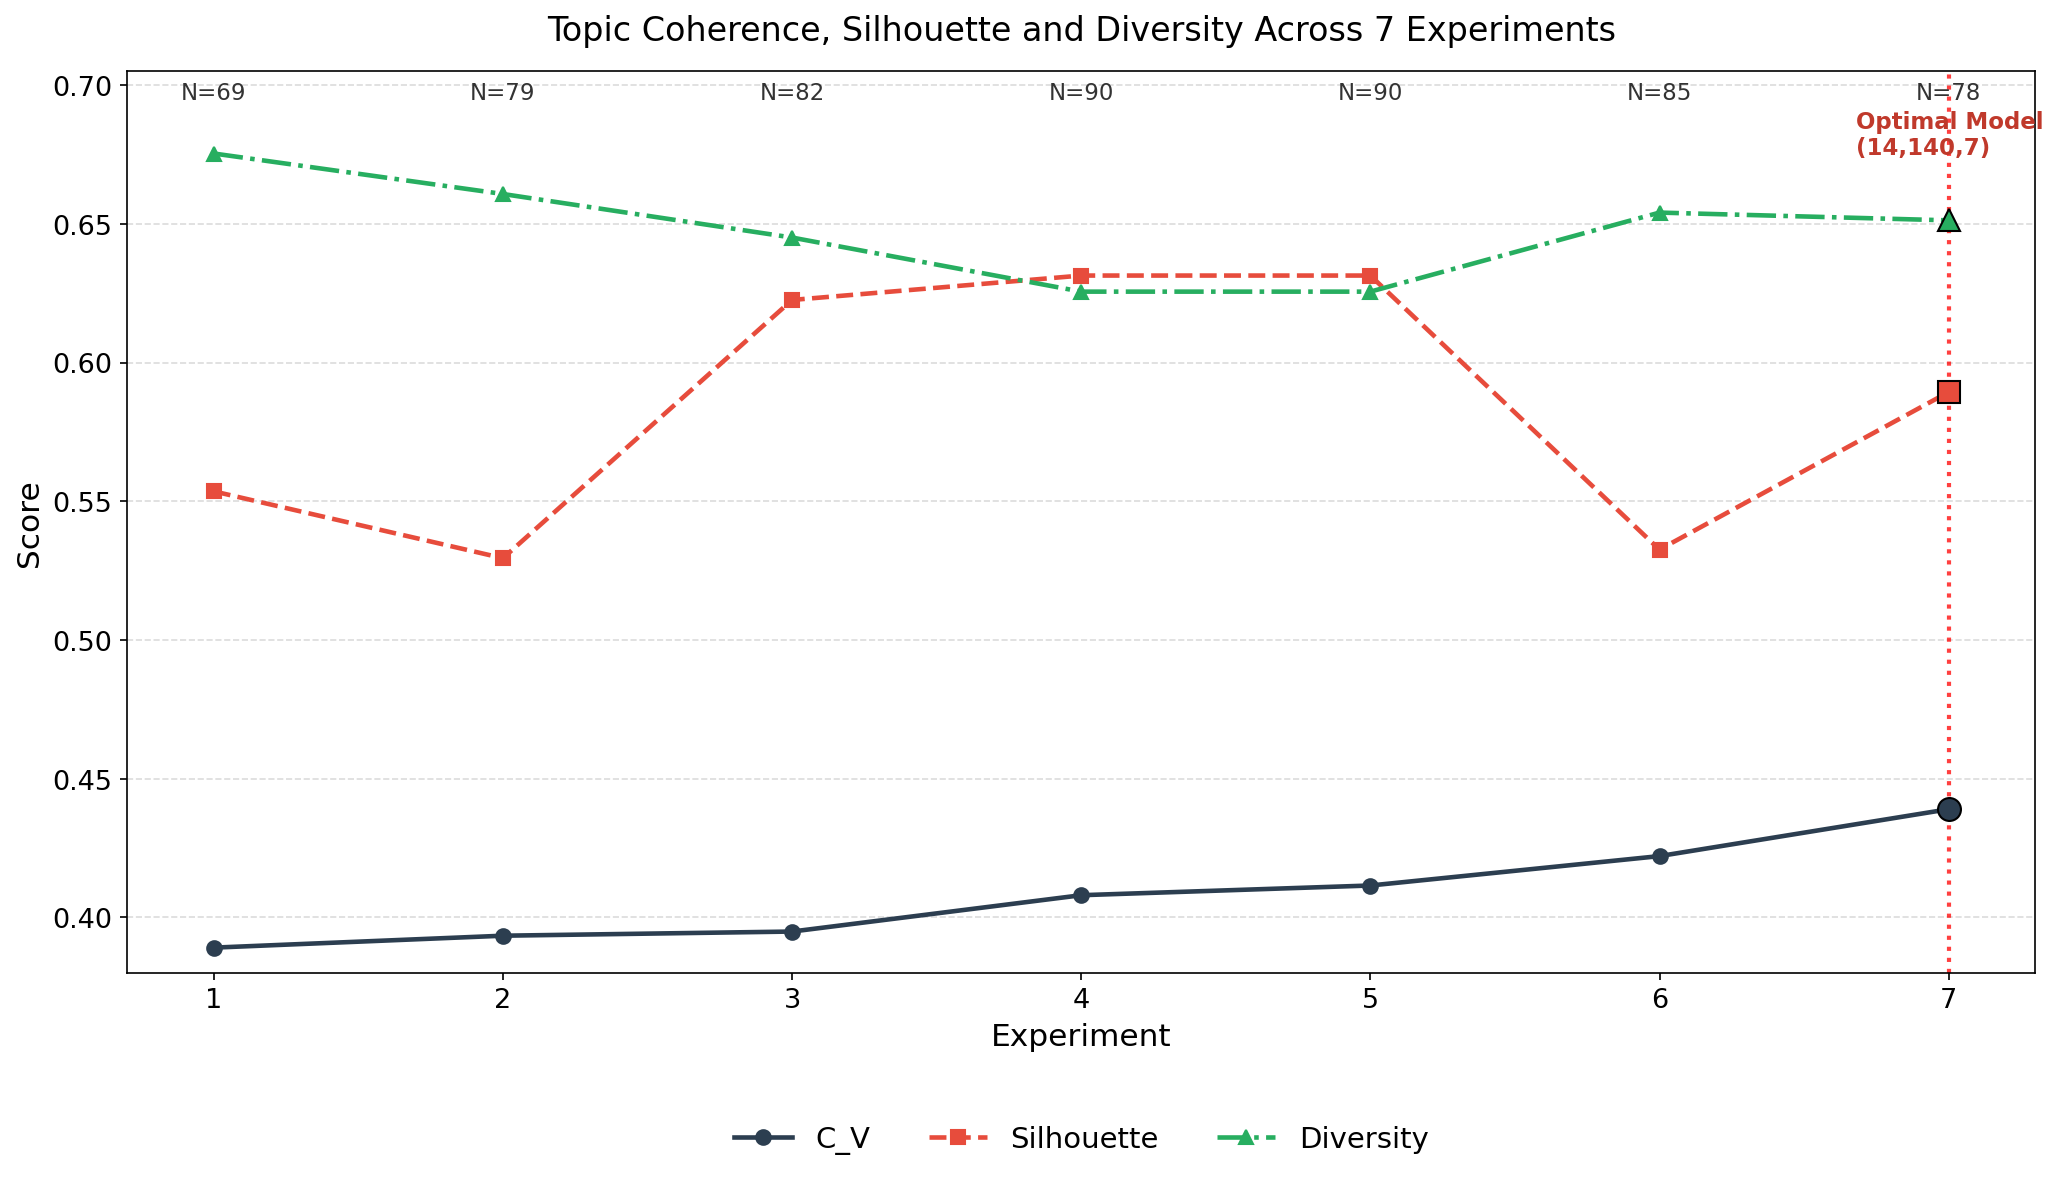

In [14]:
import matplotlib.pyplot as plt
import numpy as np
# ========== 数据（7组实验） ==========
exp = [1, 2, 3, 4, 5, 6, 7]
cv = [0.3891, 0.3934, 0.3949, 0.408, 0.4115, 0.4221, 0.439]
sil = [0.5536, 0.5295, 0.6226, 0.6314, 0.6314, 0.5326, 0.5894]
diversity = [0.6754, 0.6608, 0.6451, 0.6256, 0.6256, 0.6541, 0.6513]
topic_num = [69, 79, 82, 90, 90, 85, 78]
# ========== 主图 ==========
fig, ax = plt.subplots(figsize=(14, 8), dpi=150)
ax.plot(exp, cv, marker='o', color='#2c3e50', linestyle='-',
        linewidth=2.2, markersize=7, label='C_V')
ax.plot(exp, sil, marker='s', color='#e74c3c', linestyle='--',
        linewidth=2.2, markersize=7, label='Silhouette')
ax.plot(exp, diversity, marker='^', color='#27ae60', linestyle='-.',
        linewidth=2.2, markersize=7, label='Diversity')
# 顶部标注主题数量
for x, n in zip(exp, topic_num):
    ax.annotate(f'N={n}', (x, 0.695), ha='center', fontsize=11, color='#333333')
# ========== 高亮主模型：第7组（索引=6） ==========
main_idx = 6
ax.plot(exp[main_idx], cv[main_idx], marker='o', markersize=11,
        markeredgecolor='black', markerfacecolor='#2c3e50', zorder=5)
ax.plot(exp[main_idx], sil[main_idx], marker='s', markersize=11,
        markeredgecolor='black', markerfacecolor='#e74c3c', zorder=5)
ax.plot(exp[main_idx], diversity[main_idx], marker='^', markersize=11,
        markeredgecolor='black', markerfacecolor='#27ae60', zorder=5)
ax.axvline(x=exp[main_idx], color='red', linestyle=':', alpha=0.75, linewidth=2)
ax.text(exp[main_idx]-0.32, 0.675, 'Optimal Model\n(14,140,7)', fontsize=11,
        color='#c0392b', fontweight='bold')
# ========== Y轴截断，突出增幅 ==========
ax.set_ylim(0.38, 0.705)
# ========== 坐标轴与图例 ==========
ax.set_xticks(exp)
ax.set_xlabel('Experiment', fontsize=15)
ax.set_ylabel('Score', fontsize=15)
ax.tick_params(axis='both', labelsize=13)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.14),
          ncol=3, fontsize=14, frameon=False)
ax.grid(axis='y', alpha=0.45, linestyle='--')
ax.set_title('Topic Coherence, Silhouette and Diversity Across 7 Experiments',
             fontsize=16, pad=15)
plt.tight_layout()
plt.savefig('bertopic_7exp_multi_metrics_optimal_exp7.png',
            dpi=300, bbox_inches='tight')
plt.show()


In [45]:
# ========== 重新生成带【词(权重)】的两张表 ==========
import pandas as pd
import os

# 1. 逐主题提取原始 (word, weight) 元组
records = []
for tid in topic_info["Topic"].tolist():
    pairs = model_global_baseline.get_topic(tid)   # [(word, weight), ...]
    # 严格格式：词(权重)，权重保留4位小数
    word_weight_str = " | ".join([f"{word}({weight:.4f})" for word, weight in pairs])
    records.append({
        "TopicID": tid,
        "Word_Weight_Pair": word_weight_str
    })

ww_df = pd.DataFrame(records)

# 2. 合并到已有 topic_meta_df
topic_meta_full = topic_meta_df.merge(ww_df, on="TopicID", how="left")

# 3. 导出人工校准表
calib_df = topic_meta_full.copy()
calib_df["meta_name_cn"] = ""
calib_df["meta_name_en"] = ""
calib_df["adjust_cluster"] = ""
calib_df["notes"] = ""

calib_path = os.path.join(out_dir, "meta_group_calibration.xlsx")
calib_df.to_excel(calib_path, index=False)
print(f"✅ 人工校准表已导出：{calib_path}")

# 4. 导出自动聚类概览表（每个meta组取前2个细主题的词(权重)样例）
overview = calib_df.groupby("auto_meta_cluster").agg(
    n_subtopics=("TopicID", "count"),
    total_docs=("DocCount", "sum"),
    sample_word_weight=("Word_Weight_Pair", lambda s: " || ".join(s.head(2)))
).reset_index()

overview_path = os.path.join(out_dir, "auto_cluster_overview.xlsx")
overview.to_excel(overview_path, index=False)
print(f"✅ 自动聚类概览表已导出：{overview_path}")
print(overview[["auto_meta_cluster", "n_subtopics", "total_docs"]])

# 5. 打印前3行做自检，确认格式
print("\n===== 格式自检（前3个主题） =====")
print(topic_meta_full[["TopicID", "Word_Weight_Pair"]].head(3).to_string(index=False))

✅ 人工校准表已导出：D:\Jupyter\final_output_global\meta_group_calibration.xlsx
✅ 自动聚类概览表已导出：D:\Jupyter\final_output_global\auto_cluster_overview.xlsx
    auto_meta_cluster  n_subtopics  total_docs
0                   0            3        6047
1                   1            5        2356
2                   2           10        9555
3                   3            7        3478
4                   4            9        3234
5                   5            6        2390
6                   6            4        1219
7                   7            5        2333
8                   8            2        1605
9                   9           10        8962
10                 10            8        3041
11                 11            2         489
12                 12            3         876
13                 13            4         804

===== 格式自检（前3个主题） =====
 TopicID                                                                                                                         

In [96]:
import pandas as pd
import numpy as np
import os

out_dir = r"D:\Jupyter\final_output_global"

# 1.合并文档、topic、meta标签
doc_info = model_global_baseline.get_document_info(docs_global)
df_doc = pd.concat([df_all.reset_index(drop=True), doc_info.reset_index(drop=True)], axis=1)

calib_final = pd.read_excel(os.path.join(out_dir, "meta_group_calibration.xlsx"))
calib_final["final_cluster"] = np.where(
    calib_final["adjust_cluster"].isna() | (calib_final["adjust_cluster"]==""),
    calib_final["auto_meta_cluster"],
    calib_final["adjust_cluster"]
)
calib_final["meta_final_cn"] = np.where(
    calib_final["meta_name_cn"].isna() | (calib_final["meta_name_cn"]==""),
    "MetaCluster_" + calib_final["final_cluster"].astype(str),
    calib_final["meta_name_cn"]
)
topic_to_meta = calib_final[["TopicID","final_cluster","meta_final_cn"]]
df_doc = df_doc.merge(topic_to_meta, left_on="Topic", right_on="TopicID", how="left")

df_doc["time"] = pd.to_datetime(df_doc["time"])
post_start = pd.Timestamp("2020-07-01")
df_doc["period"] = np.where(df_doc["time"] >= post_start, "post", "pre")

df_valid = df_doc[df_doc["Topic"] != -1].copy()

# 2.改进抽样函数：小topic全取，大topic上限15条，不再用百分比
def sample_by_topic_fixed(group, max_sample=15, seed=42):
    n = len(group)
    take_n = min(n, max_sample)
    return group.sample(n=take_n, random_state=seed)

sample_global = df_valid.groupby("Topic", group_keys=False).apply(sample_by_topic_fixed)

sample_global["coder_topic_match"] = ""   # 匹配 / 不匹配 / 模糊
sample_global["coder_notes"] = ""

sample_global.to_excel(os.path.join(out_dir, "human_coding_sample_global.xlsx"), index=False)
print(f"✅ 全局主题核验抽样表已导出，总抽样条数：{len(sample_global)}")


✅ 全局主题核验抽样表已导出，总抽样条数：1350


In [97]:
# ====== 在已有代码后追加，不重跑建模 ======
# topic_meta_df 已存在于内存，包含 TopicID, auto_meta_cluster, Word_Weight_Pair

# 每个cluster对应的TopicID列表
cluster_topic_list = topic_meta_df.groupby("auto_meta_cluster")["TopicID"].apply(
    lambda x: ", ".join(map(str, sorted(x)))
).reset_index(name="subtopic_ids")

# 读取已有的overview表
overview = pd.read_excel(os.path.join(out_dir, "auto_cluster_overview.xlsx"))

# 合并
overview = overview.merge(cluster_topic_list, on="auto_meta_cluster", how="left")

# 保存
overview.to_excel(os.path.join(out_dir, "auto_cluster_overview.xlsx"), index=False)
print("✅ 已补充 subtopic_ids 列")
print(overview[["auto_meta_cluster", "n_subtopics", "total_docs", "subtopic_ids"]].to_string(index=False))


✅ 已补充 subtopic_ids 列
 auto_meta_cluster  n_subtopics  total_docs                                                      subtopic_ids
                 0           10        4690                             6, 12, 20, 39, 49, 56, 58, 67, 71, 75
                 1           18       15482 0, 2, 3, 4, 5, 10, 14, 28, 32, 42, 45, 60, 61, 77, 79, 81, 85, 88
                 2           14       10897               1, 7, 9, 11, 18, 23, 26, 29, 46, 50, 51, 53, 59, 65
                 3           10        5320                             8, 16, 17, 25, 30, 31, 37, 48, 70, 83
                 4            5        1415                                                19, 44, 64, 68, 84
                 5           12        3969                    13, 15, 27, 35, 43, 63, 69, 72, 74, 82, 86, 87
                 6            5        1380                                                33, 36, 54, 66, 73
                 7            8        2722                                    21, 22, 24, 41, 57, 

In [98]:
# ====== 追加cell：补充每个subtopic及其文档数到overview ======

# 1. 已有 topic_meta_df，按auto_meta_cluster聚合
def format_subtopics(group_df):
    items = [f"{row.TopicID}({int(row.DocCount)})" for _, row in group_df.iterrows()]
    return ", ".join(items)

subtopic_str = topic_meta_df.groupby("auto_meta_cluster").apply(
    format_subtopics
).reset_index(name="subtopic_id_with_doccount")

# 2. 读取现有overview，合并
overview = pd.read_excel(os.path.join(out_dir, "auto_cluster_overview.xlsx"))
overview = overview.merge(subtopic_str, on="auto_meta_cluster", how="left")

# 3. 同时输出长表（附录用）
long_table = topic_meta_df[["auto_meta_cluster", "TopicID", "DocCount"]].sort_values(
    ["auto_meta_cluster", "TopicID"]
)
long_table.to_excel(os.path.join(out_dir, "subtopic_doccount_detail.xlsx"), index=False)

# 4. 保存
overview.to_excel(os.path.join(out_dir, "auto_cluster_overview.xlsx"), index=False)

print("✅ 已补充 subtopic_id_with_doccount 列")
print(overview[["auto_meta_cluster", "n_subtopics", "total_docs", "subtopic_id_with_doccount"]].to_string(index=False))


✅ 已补充 subtopic_id_with_doccount 列
 auto_meta_cluster  n_subtopics  total_docs                                                                                                                                         subtopic_id_with_doccount
                 0           10        4690                                                                         6(1456), 12(1064), 20(624), 39(325), 49(269), 56(232), 58(220), 67(180), 71(165), 75(155)
                 1           18       15482 0(3589), 2(2059), 3(1892), 4(1716), 5(1532), 10(1268), 14(823), 28(499), 32(436), 42(307), 45(284), 60(196), 61(193), 77(150), 79(145), 81(142), 85(130), 88(121)
                 2           14       10897                                     1(3413), 7(1436), 9(1279), 11(1125), 18(669), 23(557), 26(522), 29(476), 46(283), 50(258), 51(252), 53(243), 59(203), 65(181)
                 3           10        5320                                                                          8(1363), 16(802), 17(759)

In [99]:
import pandas as pd
import os
from bertopic import BERTopic

out_dir = r"D:\Jupyter\final_output_global"

# ========== 原有你已经跑通的代码 ==========
df_all = pd.read_excel("Now_Wuhan_PlanA_Cleaned.xlsx")
docs_global = df_all["cleaned_docs"].tolist()
print(f"全局总文档数：{len(docs_global)}")

# 立刻保存模型
model_global_baseline.save(os.path.join(out_dir, "bertopic_global_baseline"))
print(f"✅主模型已保存，有效主题数: {len(model_global_baseline.get_topic_info())-1}")

# ========== 1. 提取全部细主题信息，无分期 ==========
topic_info = model_global_baseline.get_topic_info()
topic_info = topic_info[topic_info["Topic"] != -1].sort_values("Topic").reset_index(drop=True)
n_topic = len(topic_info)
print(f"有效细主题数量: {n_topic}")

# ========== 新增：获取每条文档对应的topic信息 ==========
doc_info = model_global_baseline.get_document_info(docs_global)
# doc_info字段: Document, Topic, Probability, Representative_document

# 把原始df_all 和 doc_info 按行索引合并（顺序一一对应）
df_doc_topic = pd.concat([
    df_all.reset_index(drop=True),
    doc_info[["Topic","Probability","Representative_document"]].reset_index(drop=True)
], axis=1)

# 增加字段：标记是否噪声主题 Topic=-1
df_doc_topic["is_noise_topic"] = df_doc_topic["Topic"] == -1

# ========== 把主题Top3关键词映射到每条文档，方便查阅 ==========
def get_topic_top3_words(topic_id):
    if topic_id == -1:
        return "Noise topic"
    words = model_global_baseline.get_topic(topic_id)
    top3 = [w[0] for w in words[:3]]
    return ", ".join(top3)

df_doc_topic["topic_top3_keywords"] = df_doc_topic["Topic"].apply(get_topic_top3_words)

# ========== 输出文件 ==========
# 1. 全量文档+topic映射表（核心输出，原始语段全部保留）
out_file_doc = os.path.join(out_dir, "global_doc_with_topic.xlsx")
df_doc_topic.to_excel(out_file_doc, index=False)
print(f"✅已输出全量文档‑topic映射表：{out_file_doc}")
print(f"输出表形状：{df_doc_topic.shape}")

# 2. 输出细主题元信息表（topic_info，用于后续meta校准）
out_file_topicinfo = os.path.join(out_dir, "global_topic_info.xlsx")
topic_info.to_excel(out_file_topicinfo, index=False)
print(f"✅已输出细主题元信息表：{out_file_topicinfo}")

# 打印样例预览
print("\n===== 预览前5行 =====")
print(df_doc_topic[["cleaned_docs","Topic","Probability","topic_top3_keywords"]].head().to_string(index=False))


2026-09-10 03:13:01,132 - BERTopic - WARNING: When you use `pickle` to save/load a BERTopic model,please make sure that the environments in which you saveand load the model are **exactly** the same. The version of BERTopic,its dependencies, and python need to remain the same.


全局总文档数：76468
✅主模型已保存，有效主题数: 90
有效细主题数量: 90
✅已输出全量文档‑topic映射表：D:\Jupyter\final_output_global\global_doc_with_topic.xlsx
输出表形状：(76468, 11)
✅已输出细主题元信息表：D:\Jupyter\final_output_global\global_topic_info.xlsx

===== 预览前5行 =====
                                                                                                                cleaned_docs  Topic  Probability                 topic_top3_keywords
   malaysian victim china met chinese delegates wuhan singapore noor hisham abdullah director-general health ministry health     -1     0.000000                         Noise topic
                                            base located inside china it's 435 miles away wuhan hasn't impacted chinese year      6     0.588222 development, factory, manufacturing
huoshenshan temporary field hospital construction seen nears completion wuhan central china's hubei province sunday feb 2020      8     1.000000        hospital, hospitals, medical
                                           supporters 

In [105]:
import pandas as pd
import os

out_dir = r"D:\Jupyter\final_output_global"

# 读取文档表
df_doc_topic = pd.read_excel(os.path.join(out_dir, "global_doc_with_topic.xlsx"))
# 读取meta校准映射
calib = pd.read_excel(os.path.join(out_dir, "meta_group_calibration.xlsx"))

# 合并meta标签到每条文档
df_meta = df_doc_topic.merge(
    calib[["TopicID", "auto_meta_cluster"]],
    left_on="Topic",
    right_on="TopicID",
    how="left"
)

# 过滤：仅保留非噪声文档 Topic != -1
df_valid = df_meta.query("Topic != -1").copy()
N_total = len(df_valid)
print(f"全部有效非噪声文档数量 N_total = {N_total}")

# ========== 分组计算：相对强度 + 置信度统计 ==========
meta_stats = df_valid.groupby("auto_meta_cluster").agg(
    doc_count=("Topic", "count"),
    prob_mean=("Probability", "mean"),
    prob_median=("Probability", "median"),
    prob_std=("Probability", "std"),
    prob_min=("Probability", "min"),
    prob_max=("Probability", "max")
).reset_index()

# 计算相对强度（0‑1，可转百分比）
meta_stats["relative_strength"] = meta_stats["doc_count"] / N_total
meta_stats["relative_strength_pct"] = meta_stats["relative_strength"] * 100

# 字段重排
meta_stats = meta_stats[
    ["auto_meta_cluster", "doc_count", "relative_strength", "relative_strength_pct",
     "prob_mean", "prob_median", "prob_std", "prob_min", "prob_max"]
].round(4)

# 输出excel
out_file = os.path.join(out_dir, "meta_strength_confidence_14.xlsx")
meta_stats.to_excel(out_file, index=False)

print("\n===== 9 个Meta元叙事 相对强度 & 置信度统计 =====")
print(meta_stats.to_string(index=False))
print(f"\n✅结果输出至：{out_file}")


全部有效非噪声文档数量 N_total = 48005

===== 9 个Meta元叙事 相对强度 & 置信度统计 =====
 auto_meta_cluster  doc_count  relative_strength  relative_strength_pct  prob_mean  prob_median  prob_std  prob_min  prob_max
               0.0       4690             0.0977                 9.7698     0.9010       1.0000    0.1517    0.4949       1.0
               1.0      15482             0.3225                32.2508     0.8518       1.0000    0.1979    0.0691       1.0
               2.0      10897             0.2270                22.6997     0.8715       0.9244    0.1486    0.1329       1.0
               3.0       5320             0.1108                11.0822     0.7488       0.7903    0.2422    0.1249       1.0
               4.0       1415             0.0295                 2.9476     0.9132       0.9744    0.1253    0.0971       1.0
               5.0       3969             0.0827                 8.2679     0.7776       0.8637    0.2412    0.1053       1.0
               6.0       1380             0.0287     

In [115]:
# ====================== Cell 5：可视化合集【全量数据集｜不区分危机前后｜论文级输出】 ======================
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib
from wordcloud import WordCloud
from collections import Counter

# ---------- 路径修改区 ----------
out_dir = r"D:\Jupyter\visual_out"
doc_file = r"D:\Jupyter\final_output_global\global_doc_with_topic.xlsx"       # global_doc_with_topic
meta_file = r"D:\Jupyter\final_output_global\meta_cluster_final_summary.xlsx" # meta_cluster_final_summary
os.makedirs(out_dir, exist_ok=True)

# ---------- 绘图全局设置（英文论文 DejaVu Sans） ----------
matplotlib.rcParams['font.sans-serif'] = ['DejaVu Sans']
matplotlib.rcParams['axes.unicode_minus'] = False
sns.set_style("whitegrid")

# ========== 读取meta汇总表，构建TopicID → meta英文名称映射 ==========
meta_df = pd.read_excel(meta_file)
topic2meta = {}
for _, row in meta_df.iterrows():
    meta_en = row["meta_name_en"]
    tid_list = [int(t.strip()) for t in row["topics"].split(",")]
    for tid in tid_list:
        topic2meta[tid] = {"meta_en": meta_en}

# ========== 读取全量文档表 ==========
doc_df = pd.read_excel(doc_file)

def map_meta_en(tid):
    if tid == -1:
        return "Noise Topic"
    return topic2meta.get(tid, {"meta_en":"Unassigned"})["meta_en"]

doc_df["meta_name_en"] = doc_df["Topic"].apply(map_meta_en)

# ============================================================
# BERTopic内置交互HTML可视化（topics_2d / hierarchy / heatmap / term_rank / barchart）
# ============================================================
def bertopic_builtin_viz(model, prefix):
    prefix_path = os.path.join(out_dir, prefix)
    # 1) UMAP‑2D主题散点
    try:
        fig = model.visualize_topics()
        fig.write_html(f"{prefix_path}_topics_2d.html")
    except Exception as e:
        print(f"  visualize_topics 跳过：{e}")
    # 2) 层级树 hierarchy
    try:
        fig = model.visualize_hierarchy()
        fig.write_html(f"{prefix_path}_hierarchy.html")
    except Exception as e:
        print(f"  visualize_hierarchy 跳过：{e}")
    # 3) 关键词条形图
    try:
        fig = model.visualize_barchart(n_words=10, title=f"{prefix} Topic Keywords")
        fig.write_html(f"{prefix_path}_barchart.html")
    except Exception as e:
        print(f"  visualize_barchart 跳过：{e}")
    # 4) 主题相似度热力图
    try:
        fig = model.visualize_heatmap()
        fig.write_html(f"{prefix_path}_heatmap.html")
    except Exception as e:
        print(f"  visualize_heatmap 跳过：{e}")
    # 5) term‑rank c‑TF‑IDF得分
    try:
        fig = model.visualize_term_rank()
        fig.write_html(f"{prefix_path}_term_rank.html")
    except Exception as e:
        print(f"  visualize_term_rank 跳过：{e}")
    print(f"✅ {prefix} 内置交互可视化完成（HTML输出：{out_dir}）")

# ============================================================
# 论文静态PNG绘图函数
# ============================================================
def paper_plots(model, doc_table, prefix, dataset_label):
    full_prefix = os.path.join(out_dir, prefix)
    valid = doc_table[doc_table['Topic'] != -1].copy()
    total_valid = len(valid)

    # ---------- 图1：细粒度Topic文档数量分布 ----------
    fig, ax = plt.subplots(figsize=(10, 5.5))
    counts = valid['Topic'].value_counts().sort_index()
    bars = ax.bar(counts.index.astype(str), counts.values,
                  color=sns.color_palette("viridis", len(counts)), edgecolor='white')
    for bar, cnt in zip(bars, counts.values):
        pct = cnt / total_valid * 100
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + total_valid * 0.008,
                f'{cnt}\n({pct:.1f}%)', ha='center', va='bottom', fontsize=9)
    ax.set_xlabel('Topic Number', fontsize=12)
    ax.set_ylabel('Number of Documents', fontsize=12)
    ax.set_title(f'Topic Distribution — {dataset_label}', fontsize=13, fontweight='bold')
    ax.set_ylim(0, max(counts.values) * 1.18)
    plt.tight_layout()
    plt.savefig(f"{full_prefix}_topic_distribution.png", dpi=300, bbox_inches='tight')
    plt.close()
    print(f"  📊 {prefix}_topic_distribution.png")

    # ---------- 图2：Meta‑narrative元叙事分布（横向柱状） ----------
    fig, ax = plt.subplots(figsize=(12,5.5))
    meta_counts = valid["meta_name_en"].value_counts()
    meta_pct = meta_counts / total_valid * 100
    bars = ax.barh(meta_counts.index, meta_counts.values, color="#4472C4")
    for bar, cnt, p in zip(bars, meta_counts.values, meta_pct.values):
        ax.text(bar.get_width()+3, bar.get_y()+bar.get_height()/2,
                f"{cnt} ({p:.1f}%)", va="center")
    ax.set_xlabel("Number of Documents", fontsize=12)
    ax.set_title(f'Meta‑narrative Distribution — {dataset_label}', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f"{full_prefix}_meta_narrative_distribution.png", dpi=300, bbox_inches='tight')
    plt.close()
    print(f"  📊 {prefix}_meta_narrative_distribution.png")

    # ---------- 图3：国家 × Topic 行归一化热力图 Top8国家 ----------
    top_countries = valid['country'].value_counts().head(8).index.tolist()
    sub = valid[valid['country'].isin(top_countries)]
    cross = pd.crosstab(sub['country'], sub['Topic'])
    cross_pct = cross.div(cross.sum(axis=1), axis=0) * 100
    fig, ax = plt.subplots(figsize=(10, 6))
    sns.heatmap(cross_pct, annot=True, fmt='.1f', cmap='YlOrRd',
                cbar_kws={'label': '% within country'}, ax=ax)
    ax.set_xlabel('Topic Number', fontsize=12)
    ax.set_ylabel('Country', fontsize=12)
    ax.set_title(f'Country × Topic Distribution (row‑normalized) — {dataset_label}',
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f"{full_prefix}_country_topic_heatmap.png", dpi=300, bbox_inches='tight')
    plt.close()
    print(f"  📊 {prefix}_country_topic_heatmap.png")

    # ---------- 图4：每个Topic Top‑10关键词分面图（标题附带Meta名称） ----------
    unique_tids = sorted(valid["Topic"].unique())
    n_topics = len(unique_tids)
    n_cols = 3
    n_rows = (n_topics + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4.5 * n_rows))
    axes = axes.flatten() if n_topics > 1 else [axes]
    for idx, tid in enumerate(unique_tids):
        words = model.get_topic(tid)[:10]
        if not words:
            continue
        ws = [w[0] for w in words][::-1]
        sc = [w[1] for w in words][::-1]
        axes[idx].barh(ws, sc, color='steelblue', edgecolor='white')
        meta_label = topic2meta[tid]["meta_en"]
        axes[idx].set_title(f'Topic {tid} | {meta_label}', fontsize=10, fontweight='bold')
        axes[idx].set_xlabel('c‑TF‑IDF Score', fontsize=9)
        axes[idx].tick_params(axis='y', labelsize=9)
    for idx in range(n_topics, len(axes)):
        axes[idx].set_visible(False)
    fig.suptitle(f'Top‑10 Keywords per Topic — {dataset_label}',
                 fontsize=14, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.savefig(f"{full_prefix}_topic_keywords_facet.png", dpi=300, bbox_inches='tight')
    plt.close()
    print(f"  📊 {prefix}_topic_keywords_facet.png")

    # ---------- 图5：主题分配概率分布直方图 ----------
    fig, ax = plt.subplots(figsize=(9, 5))
    sns.histplot(valid['Probability'], bins=30, kde=True, color='darkseagreen', ax=ax)
    med_val = valid['Probability'].median()
    ax.axvline(med_val, color='crimson', linestyle='--', label=f'Median = {med_val:.3f}')
    ax.set_xlabel('Topic Assignment Probability', fontsize=12)
    ax.set_ylabel('Number of Documents', fontsize=12)
    ax.set_title(f'Document‑Topic Assignment Confidence — {dataset_label}',
                 fontsize=13, fontweight='bold')
    ax.legend(fontsize=11)
    plt.tight_layout()
    plt.savefig(f"{full_prefix}_probability_distribution.png", dpi=300, bbox_inches='tight')
    plt.close()
    print(f"  📊 {prefix}_probability_distribution.png")

    # ---------- 图6：主题词云分面 ----------
    try:
        n_cols = 3
        n_rows = (n_topics + n_cols - 1) // n_cols
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 6 * n_rows))
        axes = axes.flatten() if n_topics > 1 else [axes]
        for idx, tid in enumerate(unique_tids):
            words = model.get_topic(tid)[:30]
            if not words:
                continue
            freq_dict = {w[0]: max(w[1],0.0) for w in words}
            wc = WordCloud(width=600, height=400, background_color='white',
                           colormap='viridis', prefer_horizontal=0.7, min_font_size=10).generate_from_frequencies(freq_dict)
            axes[idx].imshow(wc, interpolation='bilinear')
            meta_label = topic2meta[tid]["meta_en"]
            axes[idx].set_title(f'Topic {tid} | {meta_label}', fontsize=11, fontweight='bold')
            axes[idx].axis('off')
        for idx in range(n_topics, len(axes)):
            axes[idx].set_visible(False)
        fig.suptitle(f'Topic Word Clouds — {dataset_label}', fontsize=15, fontweight='bold', y=1.01)
        plt.tight_layout()
        plt.savefig(f"{full_prefix}_wordclouds.png", dpi=300, bbox_inches='tight')
        plt.close()
        print(f"  📊 {prefix}_wordclouds.png")
    except Exception as e:
        print(f"  ⚠️ {prefix} 词云图跳过: {e}")

    print(f"✅ {prefix} 论文级静态PNG全部完成")

# ======================== 执行入口：全量数据集，不做时间切分 ========================
print("\n" + "="*65)
print(">>> 全量数据集可视化（不区分危机/后疫情）")

# ⚠️ 内存中必须已经加载好全局模型对象 model_global
bertopic_builtin_viz(model_global, "full_dataset")
paper_plots(model_global, doc_df, "full_dataset", "Full Dataset (2020‑02 to 2025‑12)")

print("\n🎉🎉🎉 全部可视化任务结束！")
print(f"输出目录：{out_dir}")
print("HTML交互图：topics_2d / hierarchy / heatmap / term_rank / barchart")
print("PNG静态图：可直接用于论文正文")



>>> 全量数据集可视化（不区分危机/后疫情）
✅ full_dataset 内置交互可视化完成（HTML输出：D:\Jupyter\visual_out）
  📊 full_dataset_topic_distribution.png
  📊 full_dataset_meta_narrative_distribution.png
  📊 full_dataset_country_topic_heatmap.png
  📊 full_dataset_topic_keywords_facet.png
  📊 full_dataset_probability_distribution.png
  📊 full_dataset_wordclouds.png
✅ full_dataset 论文级静态PNG全部完成

🎉🎉🎉 全部可视化任务结束！
输出目录：D:\Jupyter\visual_out
HTML交互图：topics_2d / hierarchy / heatmap / term_rank / barchart
PNG静态图：可直接用于论文正文


In [118]:
print("="*70)
print("【动态主题演化｜从global_doc_with_topic聚合｜双子图】")
print("="*70)
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# ========== 1. 读取文件 ==========
df_doc = pd.read_excel(r"D:\Jupyter\final_output_global\global_doc_with_topic.xlsx")
calib  = pd.read_excel(r"D:\Jupyter\final_output_global\meta_cluster_final_summary.xlsx")

print("✅ 文档表列名:", df_doc.columns.tolist())
print("✅ Meta校准表列名:", calib.columns.tolist())


【动态主题演化｜从global_doc_with_topic聚合｜双子图】
✅ 文档表列名: ['No.', 'time', 'source', 'country', 'text', 'cleaned_docs', 'Topic', 'Probability', 'Representative_document', 'is_noise_topic', 'topic_top3_keywords']
✅ Meta校准表列名: ['final_meta', 'topic_count', 'total_docs', 'topics', 'meta_name_cn', 'meta_name_en', 'pct']


In [124]:
# ====================== Meta‑narrative Temporal Evolution｜仅9个Meta主题，按年度聚合 ======================
import os
import pandas as pd
import matplotlib.pyplot as plt

# 路径
out_dir = r"D:\Jupyter\visual_out"
doc_file = r"D:\Jupyter\final_output_global\global_doc_with_topic.xlsx"
meta_file = r"D:\Jupyter\final_output_global\meta_cluster_final_summary.xlsx"
os.makedirs(out_dir, exist_ok=True)

# 绘图全局
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False

# 读取文件
doc_df = pd.read_excel(doc_file)
meta_df = pd.read_excel(meta_file)

# 构建 TopicID → meta_name_en映射
topic2meta_en = {}
for _, row in meta_df.iterrows():
    meta_en = row["meta_name_en"]
    tid_list = [int(t.strip()) for t in row["topics"].split(",")]
    for tid in tid_list:
        topic2meta_en[tid] = meta_en

# 映射meta英文名称
doc_df["meta_name_en"] = doc_df["Topic"].map(lambda x: topic2meta_en.get(x) if x != -1 else None)

# 只保留9个meta主题，过滤噪声Topic=-1、未分配主题
all_9_meta = meta_df["meta_name_en"].unique().tolist()
valid_df = doc_df[doc_df["meta_name_en"].isin(all_9_meta)].copy()
print(f"✅ 共加载9个Meta‑narrative：{all_9_meta}")
print(f"✅ 有效文档数量（仅9个meta）：{len(valid_df)}")

# 解析时间，从time列提取【年份】
valid_df["time"] = pd.to_datetime(valid_df["time"], errors="coerce")
valid_df = valid_df.dropna(subset=["time"])
valid_df["year"] = valid_df["time"].dt.year.astype(int)

# --------------------------划分：疫情相关 / 非疫情（9个meta内部分组）--------------------------
pandemic_meta = [
    "Virus Origin Controversy & Lab Leak Narrative",
    "COVID Outbreak & Lockdown Governance",
    "Public Sentiment & Social Controversies",
    "Disease Symptoms & Clinical Features",
    "Virus Research & Biosafety Governance",
    "International Repatriation",
    "Student Repatriation & Diplomatic/Social Events",
    "Traffic Control & Travel Restrictions"
]
non_pandemic_meta = [
    "Urban Industry & Livelihood Economy"
]

# ========== 按【年份 + meta】聚合频次 ==========
year_meta = valid_df.groupby(["year", "meta_name_en"]).size().reset_index(name="Frequency")

# 拆分两组数据
df_pan = year_meta[year_meta["meta_name_en"].isin(pandemic_meta)]
df_non = year_meta[year_meta["meta_name_en"].isin(non_pandemic_meta)]

# 绘图：上下双子图
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 12), dpi=300)

# 配色
color_pandemic = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b", "#e377c2", "#7f7f7f"]
color_non = ["#bcbd22"]

# 上图：疫情相关Meta
for idx, meta in enumerate(pandemic_meta):
    sub = df_pan[df_pan["meta_name_en"] == meta].sort_values("year")
    if len(sub) == 0:
        print(f"⚠️ Meta [{meta}] 无年度数据，跳过")
        continue
    ax1.plot(sub["year"], sub["Frequency"], marker='o', markersize=6,
             linewidth=1.8, color=color_pandemic[idx], label=meta)

ax1.set_title("(a) Temporal Evolution of Pandemic‑Related Meta‑Narratives", fontsize=14, pad=14)
ax1.set_ylabel("Number of Documents", fontsize=12)
ax1.legend(frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
ax1.grid(axis='y', linestyle='--', alpha=0.5)
ax1.set_xticks(sorted(year_meta["year"].unique()))

# 下图：非疫情Meta
for idx, meta in enumerate(non_pandemic_meta):
    sub = df_non[df_non["meta_name_en"] == meta].sort_values("year")
    ax2.plot(sub["year"], sub["Frequency"], marker='o', markersize=6,
             linewidth=1.8, color=color_non[idx], label=meta)

ax2.set_title("(b) Temporal Evolution of Non‑Pandemic Meta‑Narratives", fontsize=14, pad=14)
ax2.set_xlabel("Year", fontsize=12)
ax2.set_ylabel("Number of Documents", fontsize=12)
ax2.legend(frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
ax2.grid(axis='y', linestyle='--', alpha=0.5)
ax2.set_xticks(sorted(year_meta["year"].unique()))

plt.tight_layout()
png_save = os.path.join(out_dir, "meta_9only_temporal_year_2panel.png")
plt.savefig(png_save, dpi=300, bbox_inches='tight')
plt.close()

# 输出年度聚合表
excel_save = os.path.join(out_dir, "meta_9only_yearly_trend.xlsx")
year_meta.to_excel(excel_save, index=False)

print(f"\n✅ 图片输出：{png_save}")
print(f"✅ 年度统计表输出：{excel_save}")
print("\n完成！仅9个Meta元叙事，按年度聚合演化绘图。")

✅ 共加载9个Meta‑narrative：['Virus Origin Controversy & Lab Leak Narrative', 'COVID Outbreak & Lockdown Governance', 'Public Sentiment & Social Controversies', 'Urban Industry & Livelihood Economy', 'Disease Symptoms & Clinical Features', 'Virus Research & Biosafety Governance', 'Student Repatriation & Diplomatic/Social Events', 'International Repatriation', 'Traffic Control & Travel Restrictions']
✅ 有效文档数量（仅9个meta）：48005

✅ 图片输出：D:\Jupyter\visual_out\meta_9only_temporal_year_2panel.png
✅ 年度统计表输出：D:\Jupyter\visual_out\meta_9only_yearly_trend.xlsx

完成！仅9个Meta元叙事，按年度聚合演化绘图。


In [125]:
# ====================== 年度新闻总量时序图（包含噪声Topic=-1，全降噪后语料，参考你样图样式） ======================
import os
import pandas as pd
import matplotlib.pyplot as plt

# 路径配置
out_dir = r"D:\Jupyter\visual_out"
doc_file = r"D:\Jupyter\final_output_global\global_doc_with_topic.xlsx"
os.makedirs(out_dir, exist_ok=True)

# 全局绘图设置（匹配样图字体DejaVu Sans）
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False

# 读取文档表（保留全部文档，包含Topic=-1噪声样本）
doc_df = pd.read_excel(doc_file)

# 解析time列
doc_df["time"] = pd.to_datetime(doc_df["time"], errors="coerce")
doc_df = doc_df.dropna(subset=["time"])
doc_df["year_month"] = doc_df["time"].dt.to_period("M").astype(str)

# 按月统计文档总数（包含噪声，全量降噪后语料）
month_count = doc_df.groupby("year_month").size().reset_index(name="Number of Articles")

# 绘图，复刻你示例图风格：蓝色圆点折线 + 红色虚线拐点
fig, ax = plt.subplots(figsize=(18,8), dpi=120)
ax.plot(month_count["year_month"], month_count["Number of Articles"], marker='o', color="#1f77b4", linewidth=2, markersize=5)

# 红色垂直分割线：2020-06 拐点，可按需修改
cutoff_month = "2020-06"
ax.axvline(x=cutoff_month, color='#d62728', linestyle='--', label=f"Cutoff: {cutoff_month}")

# 坐标轴与标题（完全对齐原图）
ax.set_title("Monthly News Volume (2020-02 to 2025-12)", fontsize=16, pad=15)
ax.set_xlabel("Month", fontsize=13)
ax.set_ylabel("Number of Articles", fontsize=13)

# X轴刻度：每2个月显示，防止拥挤，标签旋转
all_ticks = month_count["year_month"].tolist()
show_ticks = all_ticks[::2]
ax.set_xticks(show_ticks)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", fontsize=9)

ax.grid(alpha=0.4, linestyle='--')
ax.legend(loc="upper right")
plt.tight_layout()

# 保存图片
png_path = os.path.join(out_dir, "full_corpus_monthly_news_volume.png")
plt.savefig(png_path, bbox_inches="tight", dpi=300)
plt.close()

# 输出月度计数表（含全部文档，包含噪声）
excel_path = os.path.join(out_dir, "full_corpus_month_count.xlsx")
month_count.to_excel(excel_path, index=False)

print(f"✅ 时序图保存到：{png_path}")
print(f"✅ 月度统计表保存到：{excel_path}")
print("\n绘图完成，已包含Topic=-1噪声样本，使用降噪后的完整语料，样式与参考图一致。")


✅ 时序图保存到：D:\Jupyter\visual_out\full_corpus_monthly_news_volume.png
✅ 月度统计表保存到：D:\Jupyter\visual_out\full_corpus_month_count.xlsx

绘图完成，已包含Topic=-1噪声样本，使用降噪后的完整语料，样式与参考图一致。


===== 全量国别统计（Top 20）=====
country  doc_count       pct
     US      16970 36.581948
     IN       6233 13.436375
     GB       4379  9.439738
     SG       2507  5.404298
     AU       2400  5.173640
     CA       1970  4.246696
     HK       1468  3.164543
     ZA       1270  2.737718
     MY       1191  2.567419
     PH       1155  2.489814
     NG        945  2.037121
     NZ        906  1.953049
     PK        778  1.677122
     LK        612  1.319278
     KE        611  1.317123
     IE        578  1.245985
     BD        536  1.155446
     QA        357  0.769579
     CN        282  0.607903
     GH        242  0.521675

总有效文档: 46389
覆盖国家/地区数: 33


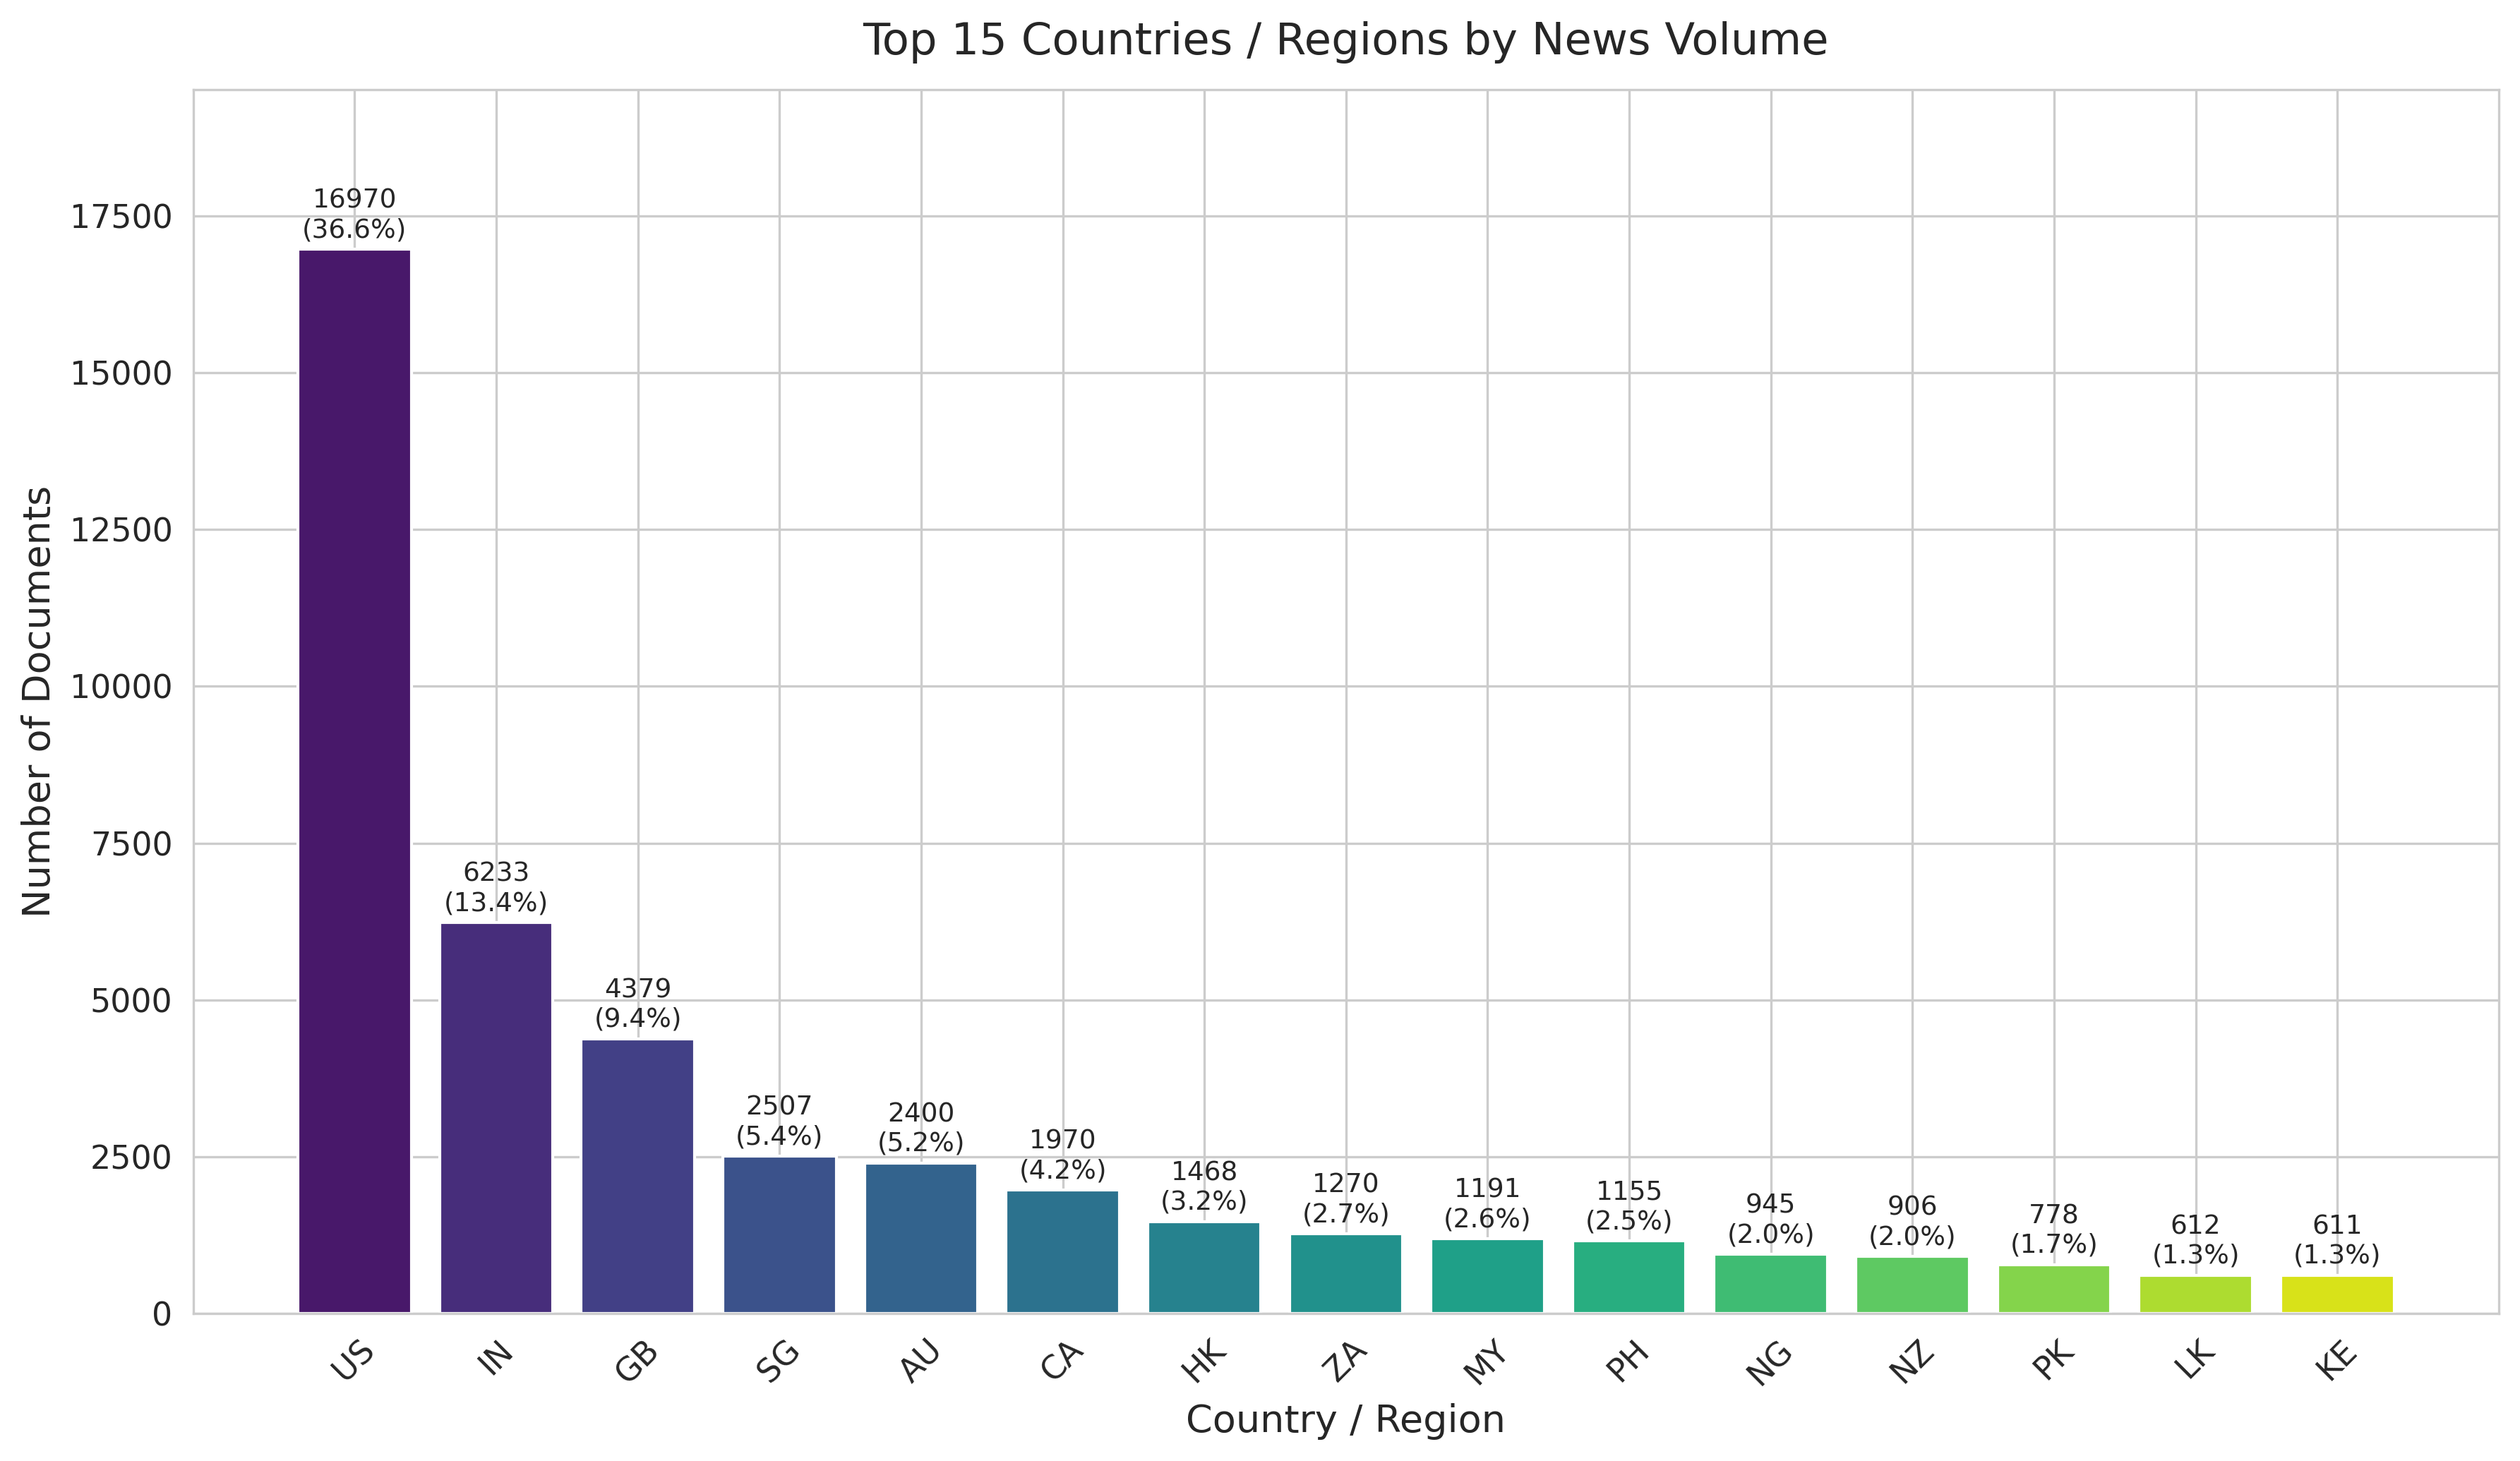

In [86]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'DejaVu Sans'

# ========== 1. 读取文档表 ==========
df = pd.read_excel(r"D:\Jupyter\final_output_global\global_doc_with_topic.xlsx")

# 过滤噪声
df_valid = df[df["Topic"] != -1].copy()

# ========== 2. 国别统计 ==========
country_counts = df_valid["country"].value_counts().reset_index()
country_counts.columns = ["country", "doc_count"]
country_counts["pct"] = country_counts["doc_count"] / len(df_valid) * 100

print("===== 全量国别统计（Top 20）=====")
print(country_counts.head(20).to_string(index=False))
print(f"\n总有效文档: {len(df_valid)}")
print(f"覆盖国家/地区数: {df_valid['country'].nunique()}")

# 导出
country_counts.to_excel(r"D:\Jupyter\final_output_global\country_distribution.xlsx", index=False)

# ========== 3. 绘制Top 15国别柱状图 ==========
top15 = country_counts.head(15)
fig, ax = plt.subplots(figsize=(12, 7), dpi=300)
bars = ax.bar(top15["country"], top15["doc_count"],
              color=sns.color_palette("viridis", len(top15)), edgecolor='white')

for bar, cnt, pct in zip(bars, top15["doc_count"], top15["pct"]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 100,
            f'{cnt}\n({pct:.1f}%)', ha='center', va='bottom', fontsize=9)

ax.set_xlabel('Country / Region', fontsize=13)
ax.set_ylabel('Number of Documents', fontsize=13)
ax.set_title('Top 15 Countries / Regions by News Volume', fontsize=15, pad=12)
ax.tick_params(axis='x', labelsize=11, rotation=45)
ax.tick_params(axis='y', labelsize=11)
ax.set_ylim(0, max(top15["doc_count"]) * 1.15)
plt.tight_layout()
plt.savefig(r"D:\Jupyter\final_output_global\country_distribution_top15.png",
            dpi=300, bbox_inches='tight')
plt.show()


In [126]:
# ====================== 国别分布饼图｜全量语料（含Topic=-1），Top10 + Others ======================
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

out_dir = r"D:\Jupyter\visual_out"
doc_file = r"D:\Jupyter\final_output_global\global_doc_with_topic.xlsx"
os.makedirs(out_dir, exist_ok=True)

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False

# 读取全量文档（含Topic=-1）
doc_df = pd.read_excel(doc_file)
total_all = len(doc_df)
print(f"全量文档数（含噪声）: {total_all:,}")

# 按国家统计
country_counts = doc_df['country'].value_counts()
print(f"国家/地区总数: {len(country_counts)}")

# Top 10 + Others
top_n = 10
top = country_counts.head(top_n)
others_count = country_counts.iloc[top_n:].sum()

labels = top.index.tolist() + ['Others']
sizes = top.values.tolist() + [others_count]

# 配色（从深紫到黄绿，和参考图bar chart一致）
colors = [
    '#4A1486', '#5E3C99', '#6A51A3', '#756BB1', '#807DBA',
    '#8C96C6', '#9EBC9F', '#7FCDBB', '#41B6C4', '#1D91C0',
    '#BDBDBD'
]

# 绘制饼图
fig, ax = plt.subplots(figsize=(12, 9), dpi=300)

wedges, texts, autotexts = ax.pie(
    sizes,
    labels=labels,
    autopct=lambda pct: f'{pct:.1f}%\n({int(round(pct/100.*sum(sizes))):,})',
    colors=colors[:len(sizes)],
    startangle=90,
    pctdistance=0.75,
    labeldistance=1.1,
    wedgeprops=dict(edgecolor='white', linewidth=1.5),
    textprops=dict(fontsize=11)
)

# 百分比文字颜色：深色块用白字，浅色块用黑字
for i, autotext in enumerate(autotexts):
    autotext.set_fontsize(9)
    if i < 6:
        autotext.set_color('white')
    else:
        autotext.set_color('#333333')

ax.set_title(f'Distribution of News Volume by Country/Region\n(Total = {total_all:,} articles, including noise)',
             fontsize=14, fontweight='bold', pad=20)

# 图例放右侧
ax.legend(wedges, [f'{l} ({v:,})' for l, v in zip(labels, sizes)],
          title='Country / Region', loc='center left', bbox_to_anchor=(1, 0, 0.5, 1),
          fontsize=10, title_fontsize=11)

plt.tight_layout()
save_path = os.path.join(out_dir, "country_distribution_pie.png")
plt.savefig(save_path, dpi=300, bbox_inches='tight')
plt.close()
print(f"✅ 饼图已保存: {save_path}")

# 同时输出国家统计表
country_counts.to_excel(os.path.join(out_dir, "country_distribution_full.xlsx"))
print(f"✅ 国家统计表已保存")


全量文档数（含噪声）: 76,468
国家/地区总数: 33
✅ 饼图已保存: D:\Jupyter\visual_out\country_distribution_pie.png
✅ 国家统计表已保存


In [2]:
# ====================== VADER 情感分析｜Now_Wuhan_PlanA_Cleaned.xlsx ======================
import pandas as pd
from nltk.sentiment import SentimentIntensityAnalyzer
import nltk

# 首次运行下载词典（已下载过可注释掉）
nltk.download('vader_lexicon')

# ---------- 1. 读取数据 ----------
df = pd.read_excel("Now_Wuhan_PlanA_Cleaned.xlsx")
print(f"总文档数: {len(df)}")
print(f"列名: {df.columns.tolist()}")

# ---------- 2. 初始化VADER ----------
sia = SentimentIntensityAnalyzer()

# ---------- 3. 对 text 列逐条打分 ----------
def vader_score(text):
    """输入原始文本，返回 neg/neu/pos/compound 四元组"""
    if pd.isna(text):
        return pd.Series([0, 0, 0, 0])
    scores = sia.polarity_scores(str(text))
    return pd.Series([scores['neg'], scores['neu'], scores['pos'], scores['compound']])

df[['vader_neg', 'vader_neu', 'vader_pos', 'vader_compound']] = df['text'].apply(vader_score)

# ---------- 4. 情感分类标签 ----------
def label(compound):
    if compound >= 0.05:
        return 'positive'
    elif compound <= -0.05:
        return 'negative'
    else:
        return 'neutral'

df['vader_label'] = df['vader_compound'].apply(label)

# ---------- 5. 输出概览 ----------
print("\n=== 情感分布 ===")
print(df['vader_label'].value_counts())
print(f"\n=== compound 描述统计 ===")
print(df['vader_compound'].describe())

# ---------- 6. 按年度聚合（配合你的meta时序分析） ----------
df['time'] = pd.to_datetime(df['time'])
df['year'] = df['time'].dt.year
yearly = df.groupby('year')['vader_compound'].agg(['mean', 'median', 'std', 'count'])
print(f"\n=== 年度平均compound ===")
print(yearly)

# ---------- 7. 保存 ----------
df.to_excel("Now_Wuhan_PlanA_Cleaned_vader.xlsx", index=False)
print(f"\n✅ 已保存: Now_Wuhan_PlanA_Cleaned_vader.xlsx")
print("   新增列: vader_neg, vader_neu, vader_pos, vader_compound, vader_label")


[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\c\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


总文档数: 76468
列名: ['time', 'source', 'country', 'text', 'cleaned_docs']

=== 情感分布 ===
vader_label
negative    27331
neutral     26879
positive    22258
Name: count, dtype: int64

=== compound 描述统计 ===
count    76468.000000
mean        -0.041942
std          0.380405
min         -0.970900
25%         -0.318200
50%          0.000000
75%          0.177900
max          0.968400
Name: vader_compound, dtype: float64

=== 年度平均compound ===
          mean  median       std  count
year                                   
2020 -0.059496     0.0  0.380661  45403
2021 -0.033207     0.0  0.367750  16960
2022 -0.035951     0.0  0.376659   5351
2023 -0.009584     0.0  0.380924   3578
2024  0.044812     0.0  0.385120   2041
2025  0.061403     0.0  0.416735   3135

✅ 已保存: Now_Wuhan_PlanA_Cleaned_vader.xlsx
   新增列: vader_neg, vader_neu, vader_pos, vader_compound, vader_label


In [4]:
# ====================== 整体+国别情感倾向计算 & 可视化【仅报道量TOP10国家/地区】 ======================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns
import os

# ---------- 输出目录 ----------
out_dir = r"D:\Jupyter\visual_out"
os.makedirs(out_dir, exist_ok=True)

# ---------- 绘图全局设置（英文论文，DejaVu Sans 无中文） ----------
matplotlib.rcParams['font.sans-serif'] = ['DejaVu Sans']
matplotlib.rcParams['axes.unicode_minus'] = False
sns.set_style("whitegrid")

# ========== 读取数据 ==========
df = pd.read_excel("Now_Wuhan_PlanA_Cleaned_vader.xlsx")

# 【重点：固定指定报道量前10国家/地区，和图例保持一致】
top10_country_list = ["US","IN","GB","SG","AU","CA","HK","MY","PH","ZA"]
df_top10 = df[df["country"].isin(top10_country_list)].copy()

# ---------- 1. 全局指标（仅TOP10样本） ----------
overall_compound_mean = df_top10['vader_compound'].mean()
overall_compound_median = df_top10['vader_compound'].median()
print("="*50)
print("【TOP10国家/地区样本】整体情感倾向")
print("="*50)
print(f"compound 均值:   {overall_compound_mean:.4f}")
print(f"compound 中位数: {overall_compound_median:.4f}")
print(f"compound 标准差: {df_top10['vader_compound'].std():.4f}")

# ---------- 2. 全局情感标签分布 ----------
label_counts = df_top10['vader_label'].value_counts()
label_pct = df_top10['vader_label'].value_counts(normalize=True) * 100
print(f"\n情感标签分布:")
for label in ['positive', 'neutral', 'negative']:
    cnt = label_counts.get(label, 0)
    pct = label_pct.get(label, 0)
    print(f"  {label:10s}: {cnt:>6d} 篇 ({pct:.1f}%)")

# ---------- 3. 全局neg/neu/pos平均分 ----------
print(f"\n平均维度得分:")
print(f"  neg 平均: {df_top10['vader_neg'].mean():.4f}")
print(f"  neu 平均: {df_top10['vader_neu'].mean():.4f}")
print(f"  pos 平均: {df_top10['vader_pos'].mean():.4f}")

# ---------- 4. 整体倾向判定 ----------
if overall_compound_mean > 0.05:
    tendency = "Overall slightly positive"
elif overall_compound_mean < -0.05:
    tendency = "Overall slightly negative"
else:
    tendency = "Overall neutral"
print(f"\n>>> 整体判定: {tendency} (mean compound = {overall_compound_mean:.4f})")

# ---------- 5. 年度情感变化（TOP10子集） ----------
df_top10['time'] = pd.to_datetime(df_top10['time'])
df_top10['year'] = df_top10['time'].dt.year
yearly = df_top10.groupby('year').agg(
    mean_compound=('vader_compound', 'mean'),
    median_compound=('vader_compound', 'median'),
    neg_pct=('vader_label', lambda x: (x == 'negative').mean() * 100),
    pos_pct=('vader_label', lambda x: (x == 'positive').mean() * 100),
    n=('vader_compound', 'count')
).round(3)
print(f"\n年度情感趋势（TOP10）:")
print(yearly.to_string())

# ---------- 6. 按国家分组统计TOP10 ----------
country_stats = df_top10.groupby("country").agg(
    mean_compound = ("vader_compound", "mean"),
    n_articles = ("vader_compound", "count"),
    neg_pct = ("vader_label", lambda x: (x=="negative").mean()*100),
    neu_pct = ("vader_label", lambda x: (x=="neutral").mean()*100),
    pos_pct = ("vader_label", lambda x: (x=="positive").mean()*100)
).round(2)
# 按照compound得分升序排序，方便绘图
country_stats = country_stats.sort_values("mean_compound")
print(f"\n===== TOP10国家/地区 情感统计 =====")
print(country_stats.to_string())

# 导出统计表
country_stats.to_excel(os.path.join(out_dir,"top10_country_vader_stats.xlsx"))

# ====================== 可视化1：TOP10国别Compound均值横向条形图 ======================
plt.figure(figsize=(10, 6), dpi=300)
sns.barplot(data=country_stats.reset_index(), y="country", x="mean_compound", color="#4472C4")
plt.axvline(x=0, color="black", linestyle="--", lw=1.2)
plt.xlabel("Mean VADER Compound Score", fontsize=12)
plt.ylabel("Country / Region", fontsize=12)
plt.title("Average Sentiment Compound Score by Top 10 Countries/Regions", fontsize=13, pad=12)
plt.tight_layout()
plt.savefig(os.path.join(out_dir, "top10_country_compound_bar.png"), bbox_inches="tight")
plt.close()

# ====================== 可视化2：TOP10国别情感占比堆叠横向柱状图 ======================
plot_df = country_stats.reset_index()
plt.figure(figsize=(12,6), dpi=300)
bar_width = 0.7
plt.barh(plot_df["country"], plot_df["neg_pct"], height=bar_width, label="Negative", color="#C0504D")
plt.barh(plot_df["country"], plot_df["neu_pct"], left=plot_df["neg_pct"], height=bar_width, label="Neutral", color="#E7E6E6")
plt.barh(plot_df["country"], plot_df["pos_pct"], left=plot_df["neg_pct"]+plot_df["neu_pct"], height=bar_width, label="Positive", color="#5B9BD5")
plt.xlabel("Proportion (%)", fontsize=12)
plt.ylabel("Country / Region", fontsize=12)
plt.title("Proportion of Sentiment Polarity by Top 10 Countries/Regions", fontsize=13, pad=12)
plt.legend(fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(out_dir, "top10_country_sentiment_stacked.png"), bbox_inches="tight")
plt.close()

print("\n✅ TOP10绘图完成！图片保存至：", out_dir)
print("图1：top10_country_compound_bar.png")
print("图2：top10_country_sentiment_stacked.png")


【TOP10国家/地区样本】整体情感倾向
compound 均值:   -0.0414
compound 中位数: 0.0000
compound 标准差: 0.3783

情感标签分布:
  positive  :  18928 篇 (29.1%)
  neutral   :  22906 篇 (35.2%)
  negative  :  23167 篇 (35.6%)

平均维度得分:
  neg 平均: 0.0555
  neu 平均: 0.8996
  pos 平均: 0.0449

>>> 整体判定: Overall neutral (mean compound = -0.0414)

年度情感趋势（TOP10）:
      mean_compound  median_compound  neg_pct  pos_pct      n
year                                                         
2020         -0.058              0.0   36.592   27.684  37093
2021         -0.033              0.0   34.861   28.930  15358
2022         -0.036              0.0   35.348   30.426   4815
2023         -0.025              0.0   35.218   30.867   3149
2024          0.025              0.0   31.168   36.467   1755
2025          0.057              0.0   31.155   40.233   2831

===== TOP10国家/地区 情感统计 =====
         mean_compound  n_articles  neg_pct  neu_pct  pos_pct
country                                                      
HK               -0.08        2560

In [5]:
# 按country看情感差异
df.groupby('country')['vader_compound'].mean().sort_values()

# 如果你后续有Topic映射表，可以合并后按meta簇看情感
# df_with_topic = pd.read_excel("global_doc_with_topic.xlsx")
# merged = pd.merge(df, df_with_topic[['text','Topic']], on='text', how='left')
# merged.groupby('Topic')['vader_compound'].mean()


country
TR   -0.120324
QA   -0.084587
NG   -0.081827
HK   -0.078240
NP   -0.072919
KE   -0.071820
BD   -0.069459
NZ   -0.062104
GH   -0.056128
PH   -0.052604
TZ   -0.050561
IN   -0.043403
JP   -0.043240
CA   -0.042841
US   -0.041931
LK   -0.041304
GB   -0.040189
MY   -0.035853
IE   -0.034624
BE   -0.033632
AU   -0.031712
ZA   -0.026050
SG   -0.025007
JM   -0.014575
IL   -0.003799
PK   -0.003371
AE    0.002882
CN    0.050754
??    0.054028
MW    0.059303
FR    0.159824
ph    0.202300
us    0.493900
Name: vader_compound, dtype: float64

In [6]:
# ====================== 整体情感倾向计算 ======================
import pandas as pd
import numpy as np

df = pd.read_excel("Now_Wuhan_PlanA_Cleaned_vader.xlsx")

# ---------- 1. 核心指标：compound均值 ----------
overall_compound_mean = df['vader_compound'].mean()
overall_compound_median = df['vader_compound'].median()
print("="*50)
print("整体情感倾向")
print("="*50)
print(f"compound 均值:   {overall_compound_mean:.4f}")
print(f"compound 中位数: {overall_compound_median:.4f}")
print(f"compound 标准差: {df['vader_compound'].std():.4f}")

# ---------- 2. 情感标签分布 ----------
label_counts = df['vader_label'].value_counts()
label_pct = df['vader_label'].value_counts(normalize=True) * 100
print(f"\n情感标签分布:")
for label in ['positive', 'neutral', 'negative']:
    cnt = label_counts.get(label, 0)
    pct = label_pct.get(label, 0)
    print(f"  {label:10s}: {cnt:>6d} 篇 ({pct:.1f}%)")

# ---------- 3. neg/neu/pos 平均占比 ----------
print(f"\n平均维度得分:")
print(f"  neg 平均: {df['vader_neg'].mean():.4f}")
print(f"  neu 平均: {df['vader_neu'].mean():.4f}")
print(f"  pos 平均: {df['vader_pos'].mean():.4f}")

# ---------- 4. 整体倾向判定 ----------
if overall_compound_mean > 0.05:
    tendency = "整体偏正面"
elif overall_compound_mean < -0.05:
    tendency = "整体偏负面"
else:
    tendency = "整体偏中性"
print(f"\n>>> 整体判定: {tendency} (mean compound = {overall_compound_mean:.4f})")

# ---------- 5. 按年度看情感变化 ----------
df['time'] = pd.to_datetime(df['time'])
df['year'] = df['time'].dt.year
yearly = df.groupby('year').agg(
    mean_compound=('vader_compound', 'mean'),
    median_compound=('vader_compound', 'median'),
    neg_pct=('vader_label', lambda x: (x == 'negative').mean() * 100),
    pos_pct=('vader_label', lambda x: (x == 'positive').mean() * 100),
    n=('vader_compound', 'count')
).round(3)
print(f"\n年度情感趋势:")
print(yearly.to_string())

# ---------- 6. 按国家看情感差异 ----------
country_sent = df.groupby('country')['vader_compound'].agg(['mean','count']).sort_values('mean')
country_sent = country_sent[country_sent['count'] >= 100]  # 过滤小样本国家
print(f"\n主要国家情感compound均值（样本≥100）:")
print(country_sent.head(10).to_string())
print("  ...")
print(country_sent.tail(5).to_string())


整体情感倾向
compound 均值:   -0.0419
compound 中位数: 0.0000
compound 标准差: 0.3804

情感标签分布:
  positive  :  22258 篇 (29.1%)
  neutral   :  26879 篇 (35.2%)
  negative  :  27331 篇 (35.7%)

平均维度得分:
  neg 平均: 0.0558
  neu 平均: 0.8990
  pos 平均: 0.0452

>>> 整体判定: 整体偏中性 (mean compound = -0.0419)

年度情感趋势:
      mean_compound  median_compound  neg_pct  pos_pct      n
year                                                         
2020         -0.059              0.0   36.883   27.588  45403
2021         -0.033              0.0   34.876   28.862  16960
2022         -0.036              0.0   35.433   30.462   5351
2023         -0.010              0.0   34.097   32.364   3578
2024          0.045              0.0   29.250   38.413   2041
2025          0.061              0.0   30.526   40.351   3135

主要国家情感compound均值（样本≥100）:
             mean  count
country                 
TR      -0.120324    285
QA      -0.084587    586
NG      -0.081827   1611
HK      -0.078240   2560
NP      -0.072919    416
KE      -0.07182

In [20]:
# ==================== 追加Cell：层次聚类交互式横向树图(HTML)，复用已训练完成的model_global ====================
import plotly.figure_factory as ff
import plotly.io as pio
from scipy.cluster.hierarchy import linkage
from sklearn.metrics.pairwise import cosine_distances

# -------------------------- 主题英文标签字典（和你之前图保持一致，按需微调标签文字）--------------------------
topic_label_dict = {
    0:"Wet Market & Wildlife Trade",
    1:"Early COVID-19 Outbreak",
    2:"Lab Leak Origin Theory",
    3:"Bat Coronavirus Research",
    4:"Virus Lab Escape Hypothesis",
    5:"Coronavirus Lab Origin Debate",
    6:"Epicenter Cases & Lockdown",
    7:"Virus Detection & Spread",
    8:"Early Deaths & Global Impact",
    9:"SARS-CoV Strain Origin",
    10:"Manufacturing & Industrial Production",
    11:"Sports Matches & Season",
    12:"Temporary Hospitals & Medical Beds",
    13:"Dr. Li Wenliang Case",
    14:"Vaccines & Virus Variants",
    15:"Public Mask-Wearing",
    16:"WIV & Shi Zhengli Reports",
    17:"Unknown Pneumonia Cluster",
    18:"International Evacuation & Quarantine",
    19:"Hospital Patient Care",
    20:"Patient Symptoms & Clinical Reports",
    21:"Quarantine & Travel Restriction",
    22:"University Research & Projects",
    23:"Journalists & Lawyers Incidents",
    24:"Lockdown Imposed & Lifted",
    25:"COVID-19 Lockdown & Restrictions",
    26:"Lab Leak Conspiracy Theory",
    27:"Pandemic Origin & Early Development",
    28:"Anti-China Virus Rhetoric",
    29:"Sports League Events",
    30:"Acute Respiratory Illness",
    31:"COVID-19 Death Toll",
    32:"Virus Variants & Mutations",
    33:"Virus Testing & Case Screening",
    34:"Pakistani Student Evacuation",
    35:"Gain-of-Function Research Debate",
    36:"Economic Impact of Pandemic",
    37:"Indian Nationals Evacuation",
    38:"School Closure & Student Management",
    39:"African Nationals Evacuation",
    40:"Airport Flights & Passenger Control",
    41:"Pompeo's Virus Remarks",
    42:"Lockdown Enforcement",
    43:"Student Return & Testing",
    44:"Military World Games",
    45:"China-India Summit (Modi-Xi Jinping)",
    46:"EcoHealth Funding Controversy",
    47:"Hospital Construction & Staff Infection",
    48:"Pandemic Documentaries",
    49:"Military & Virus Origin Claims",
    50:"Leader's Pandemic Inspection Visit",
    51:"Pandemic Response & Information Control",
    52:"Imported Cases",
    53:"Festival & Outdoor Leisure",
    54:"Australian Evacuation",
    55:"Catering & Retail Consumption",
    56:"Canadian Chartered Evacuation",
    57:"Zero-COVID & Lockdown Policy",
    58:"Spring Festival Travel & Reunion",
    59:"Stranded Student Evacuation",
    60:"Cruise Passenger Cases",
    61:"Expert Safety Assessment",
    62:"International Travel Bans",
    63:"Autonomous Driving Industry",
    64:"Joint Expert Investigation",
    65:"Early Cases & Research Debate",
    66:"Wet Market Origin Hypothesis",
    67:"Lab Virus Risk Debate",
    68:"Railway Station Passengers",
    69:"Fang Fang & Pandemic Literature",
    70:"Severe Respiratory & Pneumonia",
    71:"Lockdown Protest Reports",
    72:"Yangtze River Landmarks",
    73:"Street Protests & Demonstrations",
    74:"Unexplained Pneumonia Cluster",
    75:"International Origin Investigation Mission",
    76:"Serum Antibody Research",
    77:"On-site Security Personnel"
}

def plot_topic_hierarchical_dendrogram_html(model, out_path, title_text):
    # 获取有效主题（剔除噪声主题-1）
    topic_info = model.get_topic_info()
    topic_info_valid = topic_info[topic_info["Topic"] != -1].copy()
    valid_topic_ids = topic_info_valid["Topic"].tolist()
    topic_embeddings = model.topic_embeddings_

    # 建立主题ID→嵌入向量映射
    tid2emb = {}
    for idx, tid in enumerate(valid_topic_ids):
        tid2emb[tid] = topic_embeddings[idx]

    # 筛选在标签字典内的主题，保证标签匹配
    usable_tids = [tid for tid in topic_label_dict.keys() if tid in tid2emb.keys()]
    emb_matrix = np.array([tid2emb[tid] for tid in usable_tids])
    leaf_labels = [f"{tid}_{topic_label_dict[tid]}" for tid in usable_tids]

    # 余弦距离 + Ward 聚类，和你之前绘图逻辑完全一致
    cos_dist = cosine_distances(emb_matrix)
    Z = linkage(cos_dist, method="ward")

    # 构建横向树状图
    fig = ff.create_dendrogram(
        emb_matrix,
        linkagefun=lambda x: Z,
        orientation="right",
        labels=leaf_labels,
        color_threshold=1.0
    )

    fig.update_layout(
        width=1400,
        height=1800,
        title={"text": title_text, "font":{"size":16}},
        xaxis_title="Semantic Distance (Cosine)",
        yaxis_title="Subtopics",
        template="plotly_white"
    )
    # 输出HTML
    pio.write_html(fig, file=out_path)
    print(f"\n✅ 交互式层次聚类树已保存：{out_path}")
    return fig

# ========== 执行绘图 ==========
html_save_path = os.path.join(out_dir, "global_subtopic_hierarchical_dendrogram.html")
fig_hier = plot_topic_hierarchical_dendrogram_html(
    model=model_global,
    out_path=html_save_path,
    title_text="Hierarchical Clustering of Subtopics — Global Wuhan-related News Corpus"
)
# 【可选】静态PNG版本，可导出高分辨率图用于论文正文
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.sans-serif'] = ['DejaVu Sans']
matplotlib.rcParams['axes.unicode_minus'] = False

def plot_topic_dendrogram_png(model, out_path, title_text):
    topic_info = model.get_topic_info()
    topic_info_valid = topic_info[topic_info["Topic"] != -1].copy()
    valid_topic_ids = topic_info_valid["Topic"].tolist()
    topic_embeddings = model.topic_embeddings_
    tid2emb = {tid: topic_embeddings[i] for i, tid in enumerate(valid_topic_ids)}
    usable_tids = [tid for tid in topic_label_dict.keys() if tid in tid2emb.keys()]
    emb_matrix = np.array([tid2emb[tid] for tid in usable_tids])
    leaf_labels = [f"{tid}_{topic_label_dict[tid]}" for tid in usable_tids]
    cos_dist = cosine_distances(emb_matrix)
    Z = linkage(cos_dist, method="ward")

    fig, ax = plt.subplots(figsize=(16,20), dpi=300)
    dendrogram(
        Z,
        labels=leaf_labels,
        orientation="right",
        leaf_font_size=8,
        color_threshold=1.0,
        above_threshold_color="#3366cc",
        ax=ax
    )
    ax.set_title(title_text, fontsize=14, fontweight="bold", pad=15)
    ax.set_xlabel("Semantic Distance (Cosine)", fontsize=12)
    plt.tight_layout()
    plt.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.close()
    print(f"✅ 静态PNG已保存：{out_path}")

png_path = os.path.join(out_dir, "global_subtopic_hierarchical_dendrogram.png")
plot_topic_dendrogram_png(model_global, png_path, "Hierarchical Clustering of Subtopics — Global Wuhan-related News Corpus")



✅ 交互式层次聚类树已保存：D:\Jupyter\visual_out\global_subtopic_hierarchical_dendrogram.html


In [23]:
import matplotlib.pyplot as plt
import matplotlib
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from sklearn.metrics.pairwise import cosine_similarity

matplotlib.rcParams['font.sans-serif'] = ['DejaVu Sans']
matplotlib.rcParams['axes.unicode_minus'] = False

def plot_topic_dendrogram_png_compact(model, out_path, title_text):
    topic_info = model.get_topic_info()
    topic_info_valid = topic_info[topic_info["Topic"] != -1].copy()
    valid_topic_ids = topic_info_valid["Topic"].tolist()
    topic_embeddings = model.topic_embeddings_
    tid2emb = {tid: topic_embeddings[i] for i, tid in enumerate(valid_topic_ids)}
    usable_tids = [tid for tid in topic_label_dict.keys() if tid in tid2emb.keys()]
    emb_matrix = np.array([tid2emb[tid] for tid in usable_tids])
    leaf_labels = [f"{tid}_{topic_label_dict[tid]}" for tid in usable_tids]

    # 1-cosine相似度作为距离，值域0~1
    sim_matrix = cosine_similarity(emb_matrix)
    dist_matrix = 1 - sim_matrix
    Z = linkage(dist_matrix, method="ward")

    fig, ax = plt.subplots(figsize=(14,18), dpi=300)
    dendro_data = dendrogram(
        Z,
        labels=leaf_labels,
        orientation="right",
        leaf_font_size=7.2,
        color_threshold=1.0,
        above_threshold_color="#3366cc",
        ax=ax
    )
    
    # 绘制浅灰色聚类背景条（原版图效果）
    max_d = 1.0
    clusters = fcluster(Z, max_d, criterion='distance')
    leaf_order = dendro_data['leaves']
    leaf_cluster_id = clusters[leaf_order]
    y_positions = np.arange(len(leaf_labels))
    unique_clusters = np.unique(clusters)
    for c in unique_clusters:
        idx_in_leaves = np.where(leaf_cluster_id == c)[0]
        if len(idx_in_leaves) ==0:
            continue
        y_min = np.min(y_positions[idx_in_leaves]) -0.45
        y_max = np.max(y_positions[idx_in_leaves]) +0.45
        ax.axhspan(y_min, y_max, facecolor='#e9ecef', alpha=0.6, zorder=0)

    ax.set_title(title_text, fontsize=14, fontweight='bold', pad=12)
    ax.set_xlabel("Semantic Distance (1 - Cosine Similarity)", fontsize=12)
    ax.set_xlim(0,1.5) #锁定x轴范围，实现紧凑树形
    plt.tight_layout()
    plt.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.close()
    print(f"✅ 紧凑版PNG已保存：{out_path}")

# 调用
png_path = os.path.join(out_dir, "global_subtopic_hierarchical_dendrogram_compact.png")
plot_topic_dendrogram_png_compact(model_global, png_path, "Hierarchical Clustering of Subtopics — Global Wuhan-related News Corpus")


✅ 紧凑版PNG已保存：D:\Jupyter\visual_out\global_subtopic_hierarchical_dendrogram_compact.png


In [4]:
df_topic_meta = pd.read_excel("meta_group_calibration_adjusted.xlsx")
print(df_topic_meta.columns.tolist())


['TopicID', 'DocCount', 'auto_meta_cluster', 'Top10_keywords', 'meta_name_cn', 'meta_name_en', 'adjust_cluster', 'notes']


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import umap
from matplotlib import rcParams
import plotly.graph_objects as go
import plotly.express as px
from sklearn.metrics.pairwise import cosine_similarity

# ========== 全局绘图统一配置（SSCI英文，固定，全部方案复用） ==========
rcParams['font.sans-serif'] = ['DejaVu Sans']
rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 300
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10

# 加载模型与主题表
from bertopic import BERTopic
model_global_baseline = BERTopic.load(r"D:\Jupyter\final_output_global\bertopic_global_baseline")
df_topic_meta = pd.read_excel("meta_group_calibration_adjusted.xlsx")
# 列：TopicID, DocCount, auto_meta_cluster, meta_name_en


In [46]:
df_meta_overview = pd.read_excel("auto_cluster_overview.xlsx")
print(df_meta_overview.columns.tolist())


['auto_meta_cluster', 'n_subtopics', 'total_docs', 'sample_keywords', 'subtopic_ids', 'subtopic_id_with_doccount']


In [116]:
# 文档级UMAP降维并导出
doc_emb_2d = umap_best.fit_transform(precomputed_embeds)
df_docs = pd.DataFrame({
    "umap1": doc_emb_2d[:,0],
    "umap2": doc_emb_2d[:,1],
    "topic_id": topics_baseline
})
df_docs.to_excel(os.path.join(out_dir,"doc_umap_coords.xlsx"), index=False)


In [117]:
import os
import pandas as pd
import numpy as np

out_dir = r"D:\Jupyter\visual_out"
os.makedirs(out_dir, exist_ok=True)

# 使用你本次建模的全局UMAP，对全文文档向量降维2D
doc_emb_2d = umap_best.fit_transform(precomputed_embeds)

# 构建文档坐标表（每条文档对应UMAP坐标+所属topic_id）
df_docs = pd.DataFrame({
    "umap1": doc_emb_2d[:,0],
    "umap2": doc_emb_2d[:,1],
    "topic_id": topics_baseline
})

df_docs.to_excel(os.path.join(out_dir, "doc_umap_coords.xlsx"), index=False)
print("✅ doc_umap_coords.xlsx 生成完成")


✅ doc_umap_coords.xlsx 生成完成


In [120]:
print("所有列名：", topic_centroid.columns.tolist())


所有列名： ['topic_id_old', 'doc_count', 'Name', 'Representation', 'Representative_Docs', 'topic_id', 'meta_cluster', 'x_center', 'y_center', 'TopicID', 'meta_cluster']


✅ 最终元叙事簇数量：14
簇编号：[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]
meta_cluster缺失数量： 0


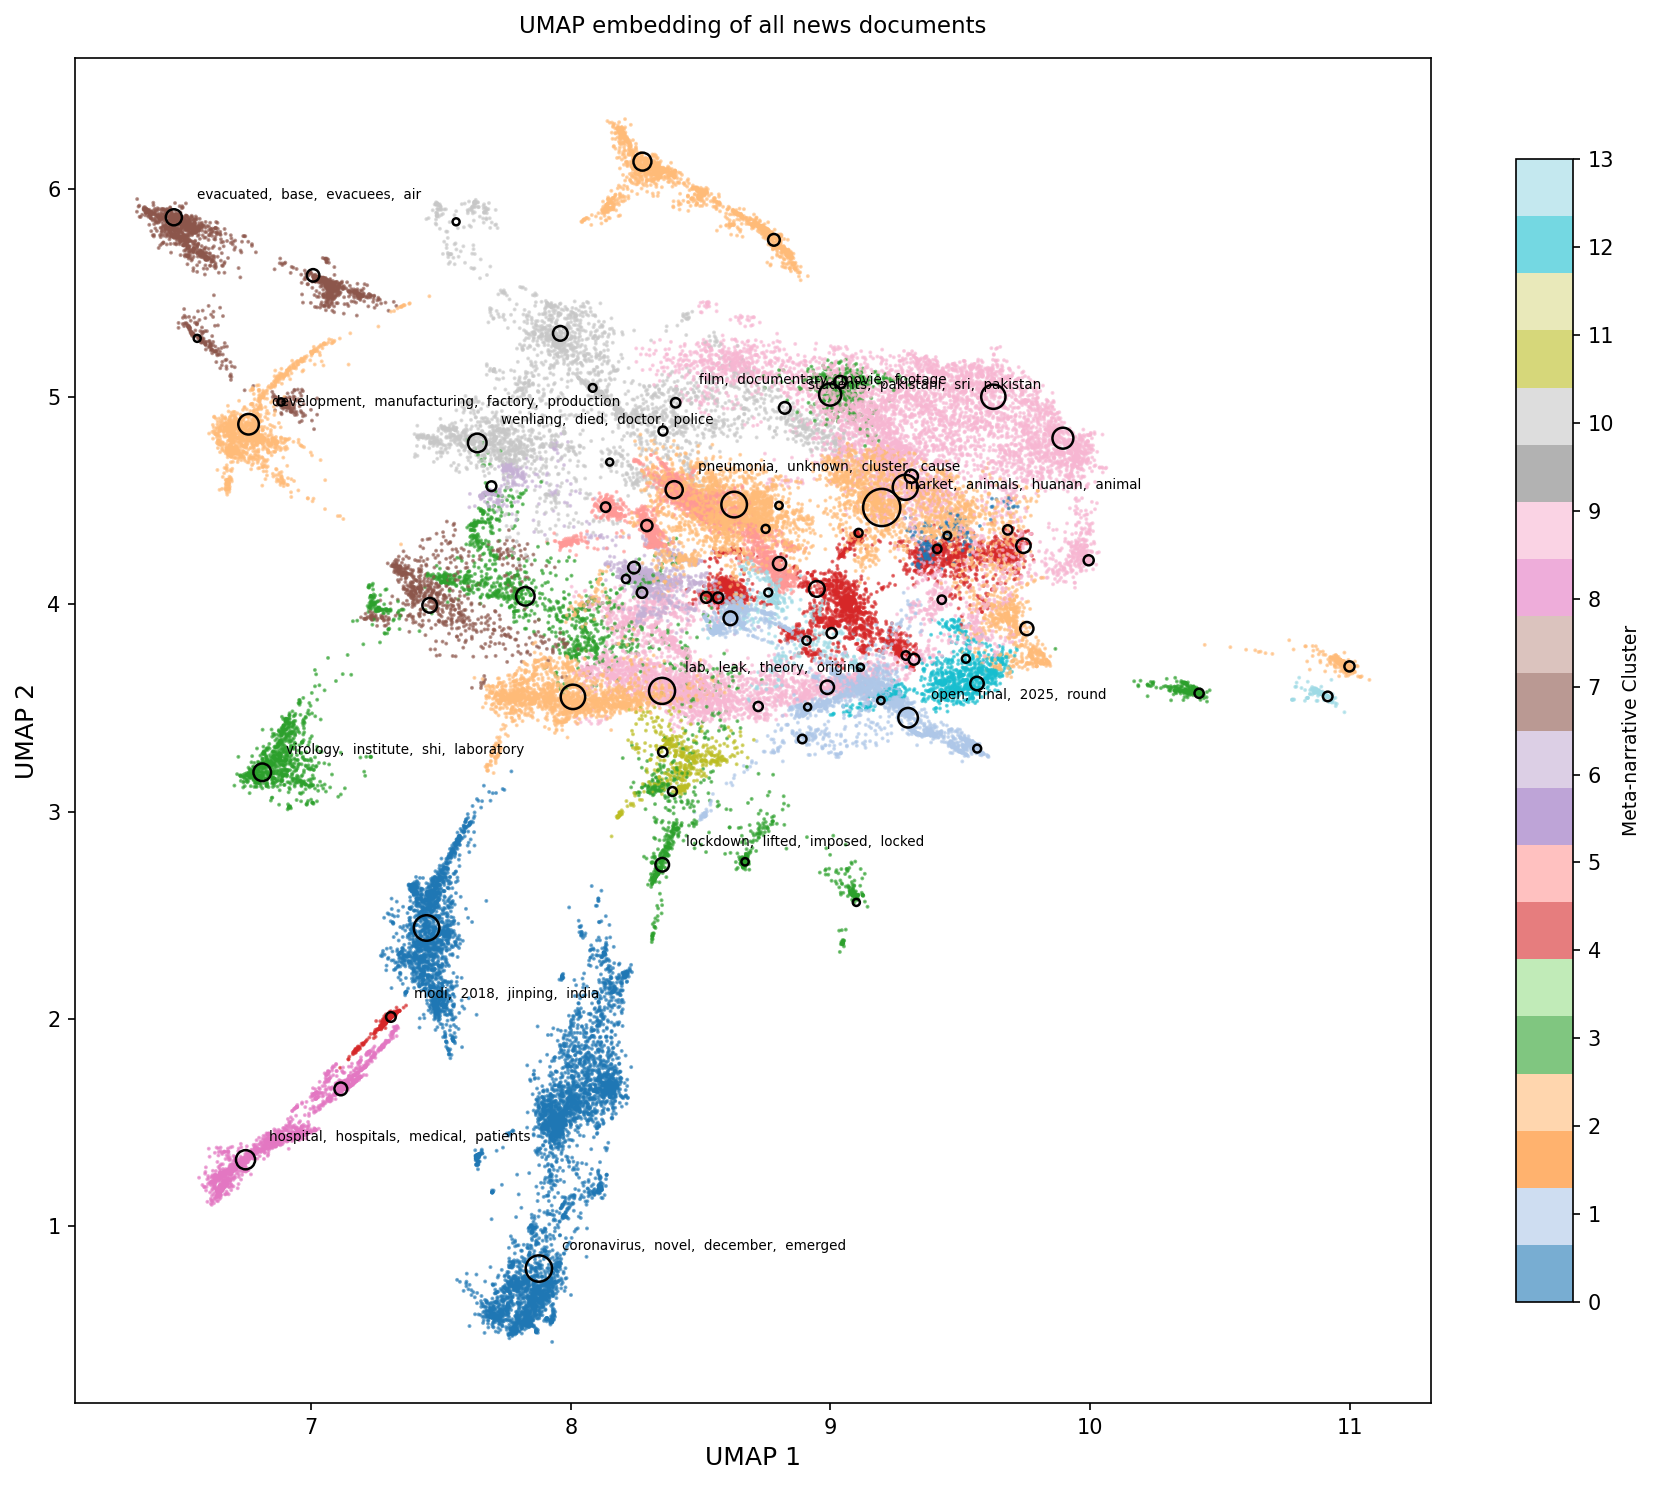

✅ 完整版UMAP大图（文档散点+子主题圆环+自动关键词标注）保存成功


In [123]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib

# ============ SSCI 绘图全局设置 ============
matplotlib.rcParams['font.sans-serif'] = ['DejaVu Sans']
matplotlib.rcParams['axes.unicode_minus'] = False
plt.rcParams['font.size'] = 10

out_dir = r"D:\Jupyter\visual_out"
data_dir = r"D:\Jupyter\final_output_global"
os.makedirs(out_dir, exist_ok=True)

# 1. 读取78子主题质心
topic_centroid = pd.read_excel(os.path.join(out_dir, "topic_centroid_78.xlsx"))

# 2. 读取元叙事分组表，提前改名避免重名冲突
meta_df = pd.read_excel(os.path.join(data_dir, "meta_group_calibration.xlsx"))
meta_df["TopicID"] = meta_df["TopicID"].astype(int)
meta_df = meta_df.rename(columns={"auto_meta_cluster":"meta_cluster_new"})

# 3. 合并，绑定元叙事
topic_centroid = topic_centroid.merge(
    meta_df[["TopicID","meta_cluster_new", "Top10_keywords"]],
    left_on="topic_id", right_on="TopicID", how="left"
)

# 删除旧的冲突meta_cluster列，只保留新合并的
if "meta_cluster" in topic_centroid.columns:
    topic_centroid = topic_centroid.drop(columns=["meta_cluster"])
topic_centroid = topic_centroid.rename(columns={"meta_cluster_new":"meta_cluster"})

# 提取唯一元叙事编号
unique_meta = sorted(pd.unique(topic_centroid["meta_cluster"]))
print(f"✅ 最终元叙事簇数量：{len(unique_meta)}")
print(f"簇编号：{unique_meta}")
print("meta_cluster缺失数量：", topic_centroid["meta_cluster"].isna().sum())

# 4. 读取全部文档UMAP坐标
df_docs = pd.read_excel(os.path.join(out_dir, "doc_umap_coords.xlsx"))

# 文档绑定元叙事标签
df_docs = df_docs.merge(
    topic_centroid[["topic_id","meta_cluster"]],
    on="topic_id", how="left"
)

# ============ 绘图（底层文档散点+上层子主题空心圆环） ============
fig, ax = plt.subplots(figsize=(12, 10), dpi=150)

# 底层：全部新闻文档淡散点
scatter = ax.scatter(
    df_docs["umap1"], df_docs["umap2"],
    c=df_docs["meta_cluster"],
    cmap="tab20",
    s=0.8, alpha=0.6
)

# 上层：78子主题空心黑圈，大小=文档量
ax.scatter(
    topic_centroid["x_center"], topic_centroid["y_center"],
    s=topic_centroid["doc_count"] * 0.08,
    edgecolors="black", facecolors="none", linewidth=1.2
)

# ============ 自动标注：每个元叙事选取文档量最大的子主题，取前4关键词 ============
anno_df = topic_centroid.loc[topic_centroid.groupby("meta_cluster")["doc_count"].idxmax()]
for _, row in anno_df.iterrows():
    kw = str(row["Top10_keywords"]).split(",")[:4]
    label_text = ", ".join(kw)
    ax.text(
        row["x_center"] + 0.09,
        row["y_center"] + 0.09,
        label_text,
        fontsize=6.5, ha="left"
    )

# 坐标轴与色条
ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
ax.set_title("UMAP embedding of all news documents", fontsize=11, pad=12)

cbar = plt.colorbar(scatter, ax=ax, shrink=0.85)
cbar.set_label("Meta-narrative Cluster", fontsize=9)
cbar.set_ticks(unique_meta)
cbar.set_ticklabels([str(i) for i in unique_meta])

plt.tight_layout()
plt.savefig(os.path.join(out_dir, "umap_full_auto_meta.png"), dpi=300, bbox_inches="tight")
plt.show()
print("✅ 完整版UMAP大图（文档散点+子主题圆环+自动关键词标注）保存成功")


✅ 最终元叙事簇数量：14
簇编号：[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]
meta_cluster缺失数量： 0


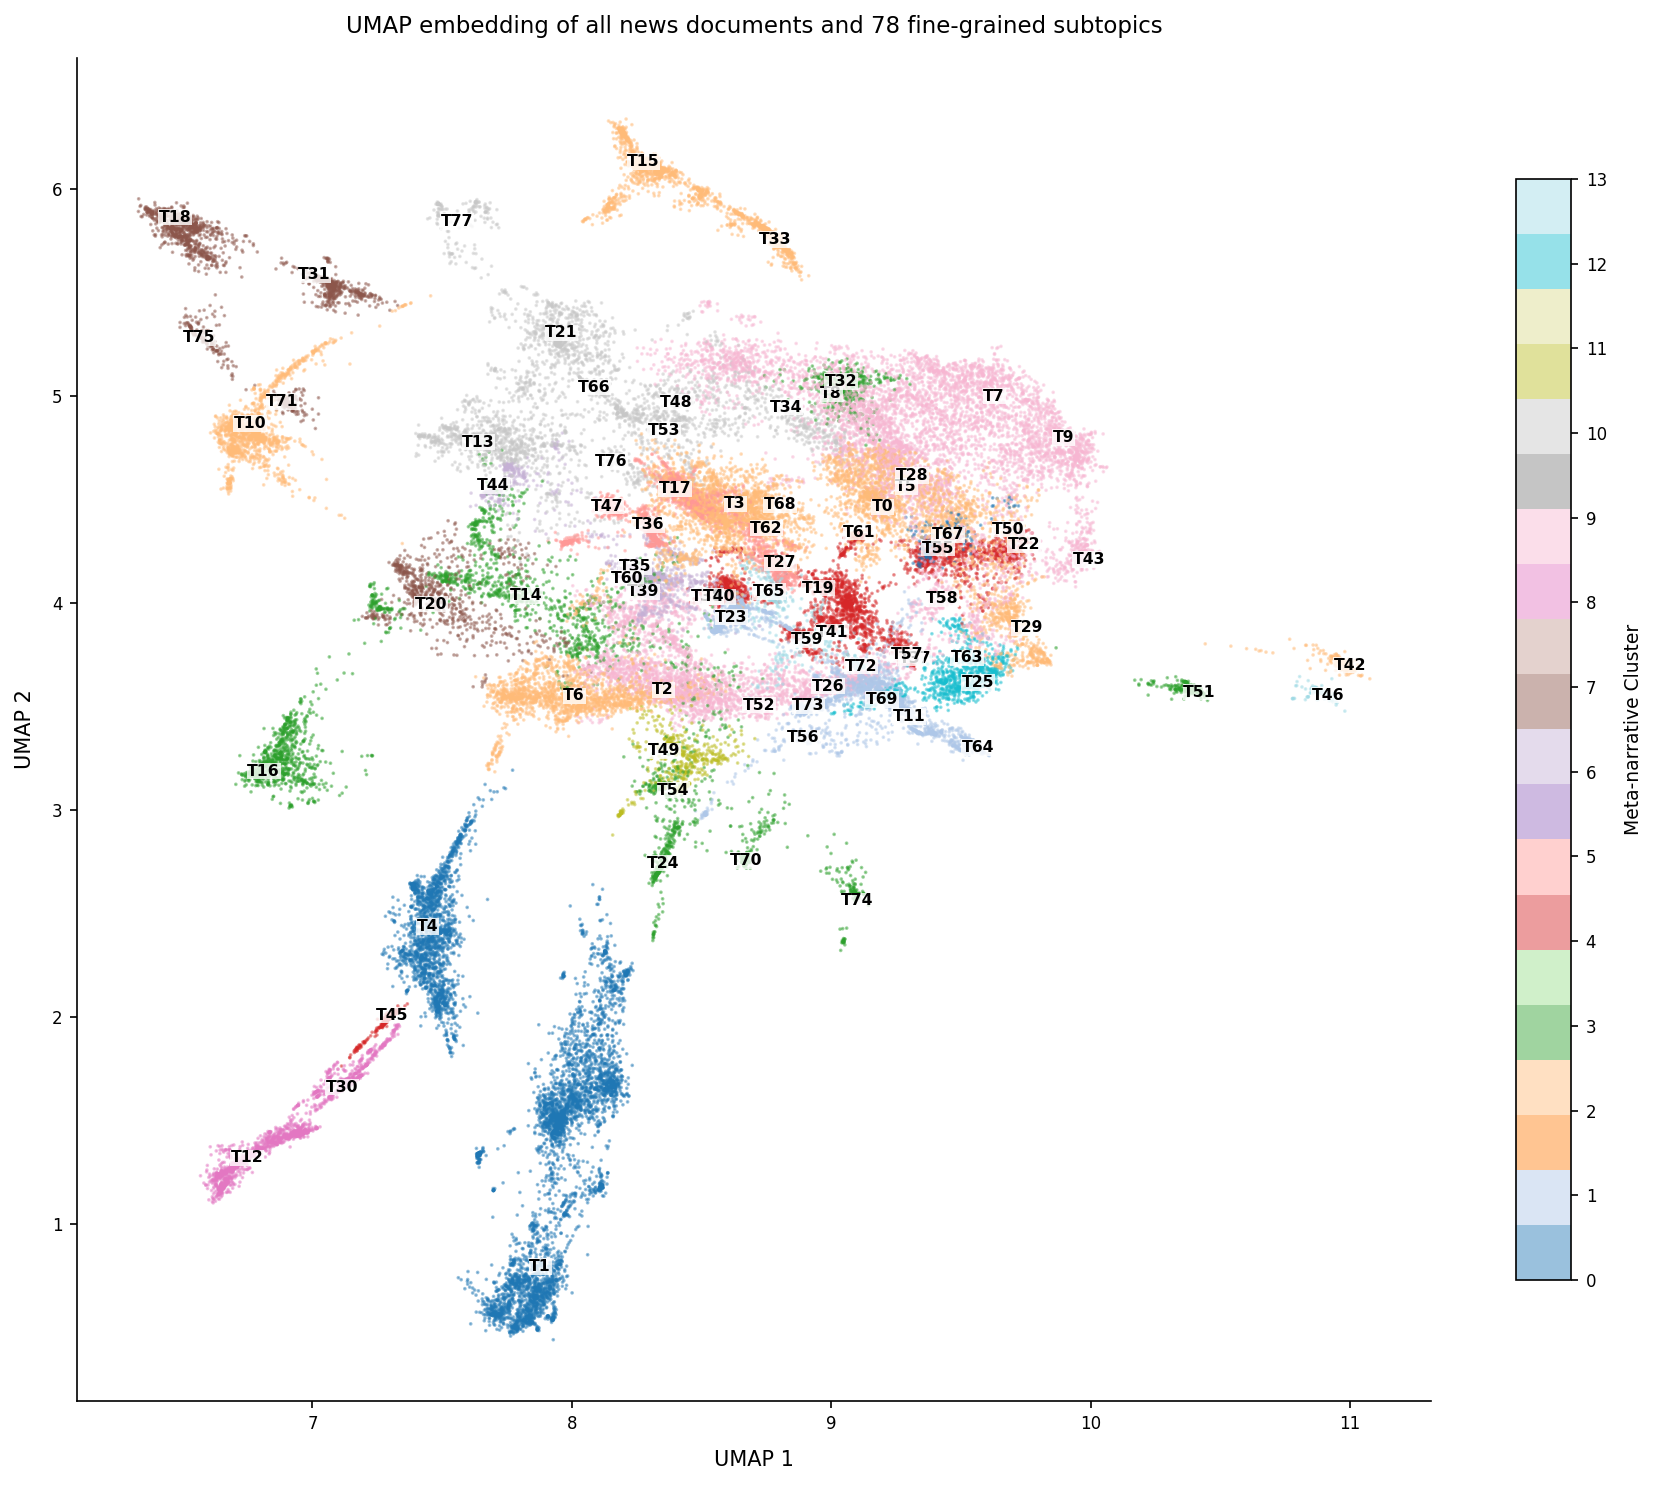

✅ 绘图完成：已移除空心圆圈，仅保留全部78个子主题T编号


In [128]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib

# ============ SSCI 绘图全局设置 ============
matplotlib.rcParams['font.sans-serif'] = ['DejaVu Sans']
matplotlib.rcParams['axes.unicode_minus'] = False
plt.rcParams['font.size'] = 10

out_dir = r"D:\Jupyter\visual_out"
data_dir = r"D:\Jupyter\final_output_global"
os.makedirs(out_dir, exist_ok=True)

# 1. 读取78子主题质心
topic_centroid = pd.read_excel(os.path.join(out_dir, "topic_centroid_78.xlsx"))

# 2. 读取元叙事分组表，提前改名避免重名冲突
meta_df = pd.read_excel(os.path.join(data_dir, "meta_group_calibration.xlsx"))
meta_df["TopicID"] = meta_df["TopicID"].astype(int)
meta_df = meta_df.rename(columns={"auto_meta_cluster":"meta_cluster_new"})

# 3. 合并，绑定元叙事
topic_centroid = topic_centroid.merge(
    meta_df[["TopicID","meta_cluster_new"]],
    left_on="topic_id", right_on="TopicID", how="left"
)

# 删除旧的冲突meta_cluster列，只保留新合并的
if "meta_cluster" in topic_centroid.columns:
    topic_centroid = topic_centroid.drop(columns=["meta_cluster"])
topic_centroid = topic_centroid.rename(columns={"meta_cluster_new":"meta_cluster"})

# 提取唯一元叙事编号
unique_meta = sorted(pd.unique(topic_centroid["meta_cluster"]))
print(f"✅ 最终元叙事簇数量：{len(unique_meta)}")
print(f"簇编号：{unique_meta}")
print("meta_cluster缺失数量：", topic_centroid["meta_cluster"].isna().sum())

# 4. 读取全部文档UMAP坐标
df_docs = pd.read_excel(os.path.join(out_dir, "doc_umap_coords.xlsx"))

# 文档绑定元叙事标签
df_docs = df_docs.merge(
    topic_centroid[["topic_id","meta_cluster"]],
    on="topic_id", how="left"
)

# ============ 绘图（移除空心圆圈，仅保留T编号） ============
fig, ax = plt.subplots(figsize=(12, 10), dpi=150)

# 底层：全部新闻文档淡散点
scatter = ax.scatter(
    df_docs["umap1"], df_docs["umap2"],
    c=df_docs["meta_cluster"],
    cmap="tab20",
    s=0.6,
    alpha=0.45
)

# ===================== 不再绘制空心圆圈 =====================
# 仅在子主题语义质心标注T编号，加粗+白底背景
for _, row in topic_centroid.iterrows():
    ax.text(
        row["x_center"], row["y_center"],
        f'T{int(row["topic_id"])}',
        fontsize=7.5,
        ha="center", va="center",
        color="black",
        weight="bold",
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=0.3)
    )

# 坐标轴、标题美化
ax.set_xlabel("UMAP 1", fontsize=10, labelpad=8)
ax.set_ylabel("UMAP 2", fontsize=10, labelpad=8)
ax.set_title(
    "UMAP embedding of all news documents and 78 fine-grained subtopics",
    fontsize=11, pad=12
)

ax.tick_params(axis="both", labelsize=8)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# 右侧色条
cbar = plt.colorbar(scatter, ax=ax, shrink=0.82)
cbar.set_label("Meta-narrative Cluster", fontsize=9, labelpad=8)
cbar.set_ticks(unique_meta)
cbar.set_ticklabels([str(i) for i in unique_meta])
cbar.ax.tick_params(labelsize=8)

plt.tight_layout()
plt.savefig(os.path.join(out_dir, "umap_full_no_circle_Tlabel.png"), dpi=300, bbox_inches="tight")
plt.show()
print("✅ 绘图完成：已移除空心圆圈，仅保留全部78个子主题T编号")
